# Phase 1

In [2]:
import pandas as pd

print("=== PHASE 1: DATE EXTRACTION & SORTING ===\n")

file_path = 'global_fuel_prices_2020_2026.csv'
df = pd.read_csv(file_path)

# Convert date and SORT DATA (Crucial for Time-Series Lags!)
df['date'] = pd.to_datetime(df['date'])
if 'country' in df.columns:
    df = df.sort_values(by=['country', 'date']).reset_index(drop=True)

# Separate date dataframe
df_dates = pd.DataFrame()
df_dates['date'] = df['date']

# Temporal features
df_dates['month'] = df_dates['date'].dt.month
df_dates['year'] = df_dates['date'].dt.year
df_dates['quarter'] = 'Q' + df_dates['date'].dt.quarter.astype(str)
df_dates['week_of_year'] = df_dates['date'].dt.isocalendar().week.astype(int)

# Remove date from main df
df = df.drop(columns=['date'])

print(f"Dataset Shape: {df.shape}")
print(f"Date Range: {df_dates['date'].min()} to {df_dates['date'].max()}")
display(df_dates.head())

=== PHASE 1: DATE EXTRACTION & SORTING ===

Dataset Shape: (27468, 9)
Date Range: 2020-01-06 00:00:00 to 2026-04-06 00:00:00


,date,month,year,quarter,week_of_year
0,2020-01-06,1,2020,Q1,2
1,2020-01-13,1,2020,Q1,3
2,2020-01-20,1,2020,Q1,4
3,2020-01-27,1,2020,Q1,5
4,2020-02-03,2,2020,Q1,6


In [3]:
print("=== PHASE A: EXPLICIT CHRONOLOGICAL TRAIN/TEST SPLIT ===\n")

# Single source of truth for the time-series split. df_dates is row-aligned to df
# (both were sorted/reset together in Phase 1), so this boolean mask applies to
# df, df_dates, df_clean, df_model interchangeably.
# Reproducibility fix: train_mask was previously USED in Phase 4 & 5 but never
# DEFINED -> "Restart & Run All" crashed with NameError. Define it once here.
SPLIT_DATE = '2025-04-01'
train_mask = (df_dates['date'] < SPLIT_DATE).to_numpy()
test_mask = ~train_mask

print(f"Split date           : {SPLIT_DATE}")
print(f"Train rows           : {train_mask.sum()}  ({train_mask.mean():.1%})")
print(f"Test  rows           : {test_mask.sum()}  ({test_mask.mean():.1%})")
print(f"Train date range     : {df_dates['date'][train_mask].min().date()} -> {df_dates['date'][train_mask].max().date()}")
print(f"Test  date range     : {df_dates['date'][test_mask].min().date()} -> {df_dates['date'][test_mask].max().date()}")

=== PHASE A: EXPLICIT CHRONOLOGICAL TRAIN/TEST SPLIT ===

Split date           : 2025-04-01
Train rows           : 23016  (83.8%)
Test  rows           : 4452  (16.2%)
Train date range     : 2020-01-06 -> 2025-03-31
Test  date range     : 2025-04-07 -> 2026-04-06


# Phase 2

In [4]:
print("=== PHASE 2: SEASON ASSIGNMENT ===\n")

def assign_season_details(region, month):
    if region in ['Europe', 'North America', 'Asia']:
        group = 'Model A (4-Seasons)'
        if month in [12,1,2]: s='Winter'
        elif month in [3,4,5]: s='Spring'
        elif month in [6,7,8]: s='Summer'
        else: s='Autumn'

    elif region in ['South America','Oceania']:
        group='Model A (4-Seasons)'
        if month in [12,1,2]: s='Summer'
        elif month in [3,4,5]: s='Autumn'
        elif month in [6,7,8]: s='Winter'
        else: s='Spring'

    elif region=='Middle East':
        group='Model B (2-Seasons)'
        s='Hot' if 4 <= month <= 10 else 'Mild'

    elif region=='Africa':
        group='Model B (2-Seasons)'
        s='Wet' if 5 <= month <=10 else 'Dry'

    else:
        group='Unknown'
        s='Unknown'

    return s, group

temp_df = pd.DataFrame({'region': df['region'], 'month': df_dates['month']})

df[['season','region_group']] = temp_df.apply(
    lambda row: pd.Series(assign_season_details(row['region'], row['month'])), axis=1
)

print(df['season'].value_counts())

=== PHASE 2: SEASON ASSIGNMENT ===

season
Winter    4366
Spring    4357
Summer    4162
Autumn    4119
Dry       3887
Wet       3634
Hot       1656
Mild      1287
Name: count, dtype: int64


season
Winter    4366
Spring    4357
Summer    4162
Autumn    4119
Dry       3887
Wet       3634
Hot       1656
Mild      1287
Name: count, dtype: int64


In [5]:
from sklearn.cluster import KMeans
import numpy as np

print("=== PHASE 2.5: EARLY WARNING SYSTEM (EWS) ALERTS ===\n")

# 1. Calculate Cross-Commodity Ratio
df['cross_ratio'] = df['diesel_usd_liter'] / df['petrol_usd_liter']

# 2. Calculate Brent Momentum (4-Week % Change)
# Update: Using your exact column name 'brent_crude_usd'
df['brent_momentum'] = df.groupby('country')['brent_crude_usd'].pct_change(periods=4)

# 3. THE LAG TRICK (Prevention of Data Leakage)
# Hum aaj ka ratio use nahi kar sakte, sirf pichle hafte (Lag 1) ka use karenge!
df['cross_ratio_lag1'] = df.groupby('country')['cross_ratio'].shift(1)
df['brent_momentum_lag1'] = df.groupby('country')['brent_momentum'].shift(1)

# 4. Drop current ratio and momentum so model doesn't cheat (Data Leakage proofing)
df = df.drop(columns=['cross_ratio', 'brent_momentum'])

# 5. Build clustering features and SCALE them.
# Problem #3 fix: K-Means is distance-based, so it MUST run on standardized features.
# On raw features (ratio ~1, momentum ~0..big) one dimension dominated and 96.6% of
# weeks collapsed into a single cluster. We StandardScale and fit on TRAIN rows only.
from sklearn.preprocessing import StandardScaler

cluster_feats = ['cross_ratio_lag1', 'brent_momentum_lag1']

# median imputation fit on TRAIN rows only (leak-free), then applied to all rows
cluster_medians = df.loc[train_mask, cluster_feats].median()
cluster_data = df[cluster_feats].fillna(cluster_medians)

ews_scaler = StandardScaler().fit(cluster_data[train_mask])
cluster_scaled = ews_scaler.transform(cluster_data)
cluster_scaled_train = cluster_scaled[train_mask]

print("Cluster features standardized (StandardScaler fit on train rows only).")
print(f"Train means ~0: {cluster_scaled_train.mean(axis=0).round(3)} | "
      f"Train stds ~1: {cluster_scaled_train.std(axis=0).round(3)}")
print("Final cluster fit + EWS_Alert_Level assignment happens after K-selection below.")

=== PHASE 2.5: EARLY WARNING SYSTEM (EWS) ALERTS ===

Cluster features standardized (StandardScaler fit on train rows only).
Train means ~0: [ 0. -0.] | Train stds ~1: [1. 1.]
Final cluster fit + EWS_Alert_Level assignment happens after K-selection below.


Cluster features standardized (StandardScaler fit on train rows only).
Train means ~0: [ 0. -0.] | Train stds ~1: [1. 1.]
Final cluster fit + EWS_Alert_Level assignment happens after K-selection below.


=== PHASE C: K-SELECTION SWEEP (silhouette + elbow) ===

K=2 | inertia=    31577.8 | silhouette=0.9002 | ARI=-0.0013 | max_share=0.995 | DEGENERATE (one cluster >90%)
K=3 | inertia=    19886.1 | silhouette=0.4169 | ARI=-0.0020 | max_share=0.574 | ok
K=4 | inertia=    14097.8 | silhouette=0.5021 | ARI=0.0121 | max_share=0.672 | ok
K=5 | inertia=    10849.0 | silhouette=0.4824 | ARI=0.0086 | max_share=0.487 | ok
K=6 | inertia=     8413.1 | silhouette=0.4925 | ARI=0.0084 | max_share=0.485 | ok
K=7 | inertia=     6681.5 | silhouette=0.5176 | ARI=0.0088 | max_share=0.475 | ok
K=8 | inertia=     5635.6 | silhouette=0.5205 | ARI=0.0088 | max_share=0.475 | ok


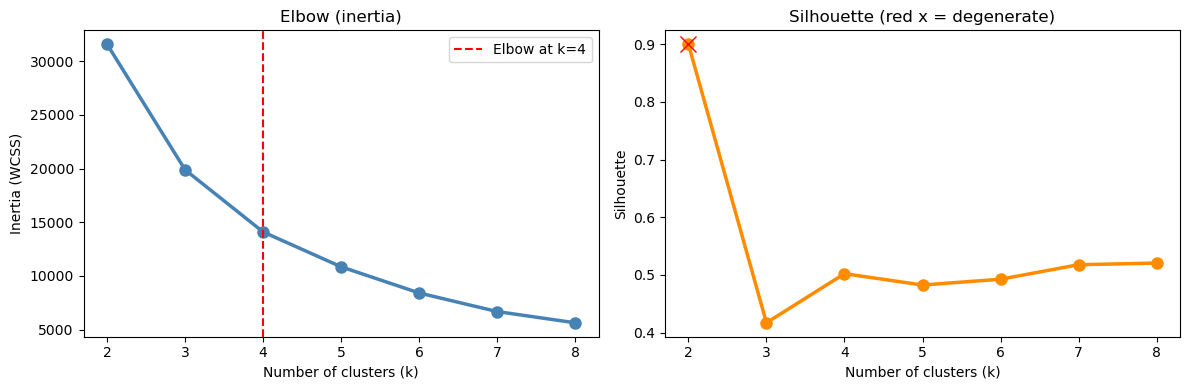


Chosen K = 4 -> non-degenerate, silhouette 0.5021 within 0.05 of best non-degenerate K=8 (0.5205); interpretable 4-level ladder.


K=8 | inertia=     5635.6 | silhouette=0.5205 | max_share=0.475 | ok


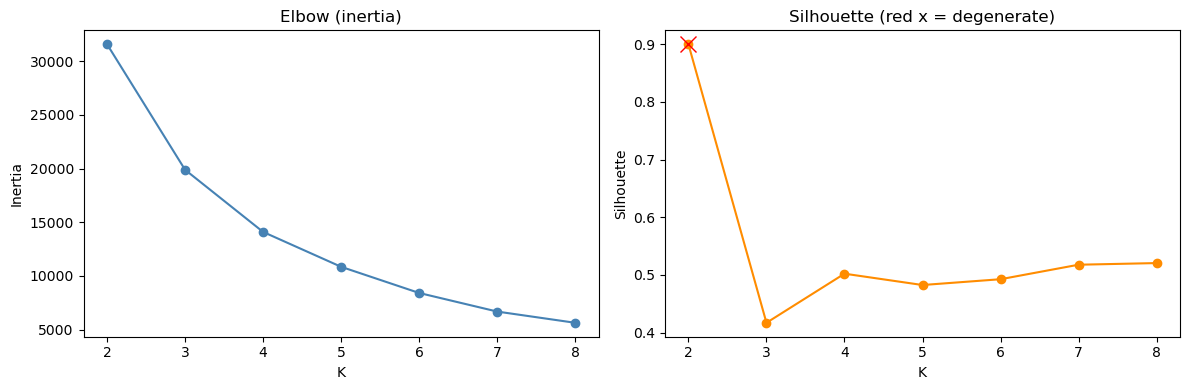


Chosen K = 4 -> non-degenerate, silhouette 0.5021 within 0.05 of best non-degenerate K=8 (0.5205); interpretable 4-level ladder.


In [6]:
from sklearn.metrics import silhouette_score, adjusted_rand_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

print("=== PHASE C: K-SELECTION SWEEP (silhouette + elbow) ===\n")

# Justify K instead of hardcoding 4. Sweep K = 2..8 on the TRAIN scaled features.
# Silhouette is scored on a fixed random subsample for speed/stability (n large).
# ARI is compared against an objective shock label derived from the same petrol-change
# rule used later in Phase E, so the sweep can evaluate cluster structure vs ground truth.
K_RANGE = range(2, 9)
rng = np.random.RandomState(42)
n_sample = min(5000, cluster_scaled_train.shape[0])
sample_idx = rng.choice(cluster_scaled_train.shape[0], size=n_sample, replace=False)
sample = cluster_scaled_train[sample_idx]

DEGEN_SHARE = 0.90   # a solution is "degenerate" if one cluster holds >90% of rows

# Ground-truth shock labels aligned to df row order.
# This mirrors the Phase E shock definition but is local to Phase C so the sweep does not
# depend on later cells.
ews_truth = pd.DataFrame({
    'country': df['country'].to_numpy(),
    'date': df_dates['date'].to_numpy(),
    'petrol': df['petrol_usd_liter'].to_numpy(),
}).sort_values(['country', 'date']).reset_index(drop=True)

g_truth = ews_truth.groupby('country')
ews_truth['chg'] = g_truth['petrol'].diff()
ews_truth['sigma'] = g_truth['chg'].transform(lambda s: s.shift(1).rolling(26, min_periods=8).std())
ews_truth['shock'] = (ews_truth['chg'].abs() > 2.0 * ews_truth['sigma']) & ews_truth['sigma'].notna()
shock_truth = ews_truth['shock'].to_numpy()

sweep = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(cluster_scaled_train)
    sil = silhouette_score(sample, km.predict(sample))
    sizes = np.bincount(km.labels_, minlength=k)
    max_share = sizes.max() / sizes.sum()
    degenerate = max_share > DEGEN_SHARE
    ari = adjusted_rand_score(shock_truth[train_mask], km.predict(cluster_scaled)[train_mask])
    sweep.append({'K': k, 'inertia': km.inertia_, 'silhouette': sil,
                  'ari': ari, 'max_cluster_share': max_share, 'degenerate': degenerate})
    flag = 'DEGENERATE (one cluster >90%)' if degenerate else 'ok'
    print(f"K={k} | inertia={km.inertia_:11.1f} | silhouette={sil:.4f} | ARI={ari:.4f} | "
          f"max_share={max_share:.3f} | {flag}")

sweep_df = pd.DataFrame(sweep)
sil_by_k = dict(zip(sweep_df['K'], sweep_df['silhouette']))

# IMPORTANT: the global silhouette max is at K=2, but that solution is DEGENERATE -
# it only isolates ~130 petrol-subsidy rows (Venezuela/Iran/Libya, petrol ~$0.01/L,
# diesel/petrol ratio 3-7x) from everything else. So the raw silhouette winner is an
# outlier artifact, not a market regime. We therefore choose K among NON-degenerate
# solutions and, since silhouette is flat there (~0.48-0.52), prefer K=4 for an
# interpretable 4-level alert ladder.
valid = sweep_df[~sweep_df['degenerate']]
best_valid_k = int(valid.loc[valid['silhouette'].idxmax(), 'K'])

best_k = int(sweep_df.loc[sweep_df['silhouette'].idxmax(), 'K'])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# -- ELBOW PLOT MODIFICATIONS --
ax[0].plot(sweep_df['K'], sweep_df['inertia'], 'o-', color='steelblue', linewidth=2.5, markersize=8)
ax[0].set(title='Elbow (inertia)', xlabel='Number of clusters (k)', ylabel='Inertia (WCSS)')

# Vertical straight dashed line add karne ka code
ax[0].axvline(x=4, color='red', linestyle='--', label='Elbow at k=4')
ax[0].legend()
# ------------------------------

ax[1].plot(sweep_df['K'], sweep_df['silhouette'], 'o-', color='darkorange', linewidth=2.5, markersize=8)
for _, r in sweep_df.iterrows():
    if r['degenerate']:
        ax[1].plot(r['K'], r['silhouette'], 'x', color='red', ms=12)
ax[1].set(title='Silhouette (red x = degenerate)', xlabel='Number of clusters (k)', ylabel='Silhouette')
plt.tight_layout(); plt.show()

if (4 in valid['K'].values) and (sil_by_k[best_valid_k] - sil_by_k[4] <= 0.05):
    CHOSEN_K = 4
    print(f"\nChosen K = 4 -> non-degenerate, silhouette {sil_by_k[4]:.4f} within 0.05 of "
          f"best non-degenerate K={best_valid_k} ({sil_by_k[best_valid_k]:.4f}); interpretable 4-level ladder.")
else:
    CHOSEN_K = best_valid_k
    print(f"\nChosen K = {best_valid_k} (best non-degenerate silhouette {sil_by_k[best_valid_k]:.4f}; "
          f"K=4 silhouette {sil_by_k.get(4):.4f}).")

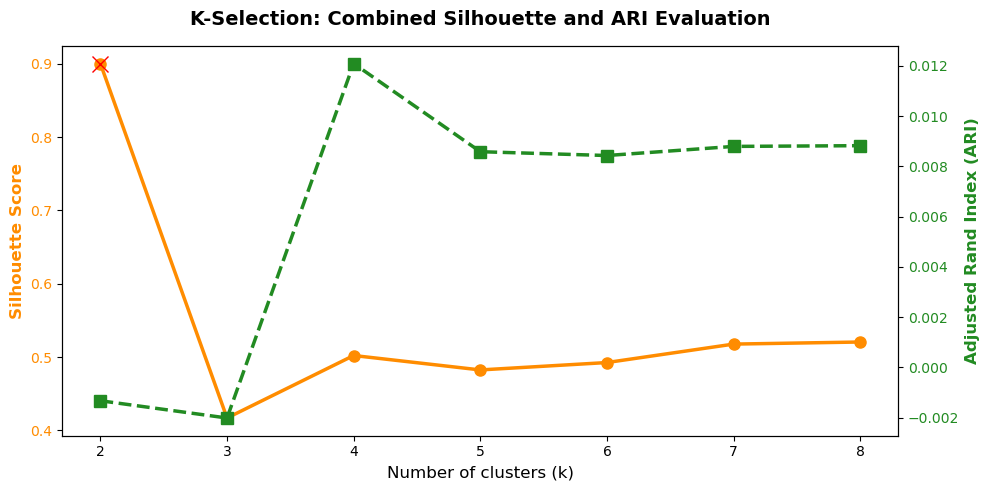

In [7]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(10, 5))

# First Plot: Silhouette Score (Left Y-Axis)
color1 = 'darkorange'
ax1.set_xlabel('Number of clusters (k)', fontsize=12)
ax1.set_ylabel('Silhouette Score', color=color1, fontsize=12, fontweight='bold')
ax1.plot(sweep_df['K'], sweep_df['silhouette'], 'o-', color=color1, linewidth=2.5, markersize=8, label='Silhouette')
ax1.tick_params(axis='y', labelcolor=color1)

# Second Plot: ARI Score (Right Y-Axis)
ax2 = ax1.twinx()  
color2 = 'forestgreen'
ax2.set_ylabel('Adjusted Rand Index (ARI)', color=color2, fontsize=12, fontweight='bold')
ax2.plot(sweep_df['K'], sweep_df['ari'], 's--', color=color2, linewidth=2.5, markersize=8, label='ARI')
ax2.tick_params(axis='y', labelcolor=color2)

# Highlight degenerate clusters (Red X marks)
for _, r in sweep_df.iterrows():
    if r['degenerate']:
        ax1.plot(r['K'], r['silhouette'], 'x', color='red', ms=12)

# Title and layout
plt.title('K-Selection: Combined Silhouette and ARI Evaluation', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.savefig('silhouette_ari_combined.png', dpi=300, bbox_inches='tight')
plt.show()

In [6]:
print("=== PHASE C: FINAL CLUSTERING + DERIVED REGIME LABELS ===\n")

# Fit final KMeans on TRAIN scaled features, then assign labels to ALL rows.
ews_kmeans = KMeans(n_clusters=CHOSEN_K, random_state=42, n_init=10).fit(cluster_scaled_train)
raw_cluster = ews_kmeans.predict(cluster_scaled)

# Centroids back in ORIGINAL units (auditable).
centroids_orig = ews_scaler.inverse_transform(ews_kmeans.cluster_centers_)
cent_df = pd.DataFrame(centroids_orig, columns=cluster_feats)
cent_df['n_rows'] = pd.Series(raw_cluster).value_counts().sort_index()

# DERIVE the regime ordering from centroids instead of assuming 0=Normal..3=Crisis.
# Alert severity = price-shock pressure, so we rank PRIMARILY by centroid Brent
# momentum (higher = more inflationary stress). Ratio extremity (distance of the
# diesel/petrol ratio from normal) is only a tiebreak; on its own it mostly flags
# static petrol-subsidy states, which are not "crises".
ratio_norm = cluster_data.loc[train_mask, 'cross_ratio_lag1'].median()
cent_df['ratio_extremity'] = (cent_df['cross_ratio_lag1'] - ratio_norm).abs()
order = (cent_df.sort_values(['brent_momentum_lag1', 'ratio_extremity'])
                .index.tolist())  # calm -> severe

if CHOSEN_K == 4:
    regime_names = ['Normal', 'Local Peak', 'Global Inflation', 'Severe Crisis']
else:
    regime_names = [f'Level {i}' for i in range(CHOSEN_K)]
    regime_names[0] += ' (calmest)'; regime_names[-1] += ' (most severe)'

# map raw cluster id -> ordered alert level (0 = calm) and a human regime name
cluster_to_level = {raw_id: lvl for lvl, raw_id in enumerate(order)}
level_to_name = {lvl: regime_names[lvl] for lvl in range(CHOSEN_K)}

df['EWS_Alert_Level'] = pd.Series(raw_cluster, index=df.index).map(cluster_to_level)
df['EWS_Regime'] = df['EWS_Alert_Level'].map(level_to_name)

cent_df['alert_level'] = cent_df.index.map(cluster_to_level)
cent_df['regime'] = cent_df['alert_level'].map(level_to_name)
cent_df = cent_df.sort_values('alert_level')

print("Centroid table (original units) -> mapping is auditable, NOT assumed:")
display(cent_df[['regime', 'alert_level', 'cross_ratio_lag1', 'brent_momentum_lag1',
                 'ratio_extremity', 'n_rows']].round(4))

print("\nNew (non-degenerate) cluster sizes by alert level:")
print(df['EWS_Alert_Level'].value_counts().sort_index())
print("\nRegime distribution:")
print(df['EWS_Regime'].value_counts())

=== PHASE C: FINAL CLUSTERING + DERIVED REGIME LABELS ===



Centroid table (original units) -> mapping is auditable, NOT assumed:


,regime,alert_level,cross_ratio_lag1,brent_momentum_lag1,ratio_extremity,n_rows
3,Normal,0,0.9349,-0.1490,0.0065,668
2,Local Peak,1,0.9238,-0.0060,0.0045,19150
1,Global Inflation,2,3.2306,0.0103,2.3023,127
0,Severe Crisis,3,0.9282,0.0616,0.0001,7523



New (non-degenerate) cluster sizes by alert level:
EWS_Alert_Level
0      668
1    19150
2      127
3     7523
Name: count, dtype: int64

Regime distribution:
EWS_Regime
Local Peak          19150
Severe Crisis        7523
Normal                668
Global Inflation      127
Name: count, dtype: int64


# Phase 3

In [7]:
import numpy as np
import pandas as pd

print("=== PHASE 3: DATA CLEANING ===\n")

df_cat = df.select_dtypes(exclude=[np.number]).copy()
df_num = df.select_dtypes(include=[np.number]).copy()

# Leakage fix: impute using statistics computed on TRAIN ROWS ONLY, then apply to
# train+test. Previously mode()/median() were fit on the full dataset (incl. test).
for col in df_cat.columns:
    fill_val = df_cat[col][train_mask].mode()[0]
    df_cat[col] = df_cat[col].fillna(fill_val)

for col in df_num.columns:
    fill_val = df_num[col][train_mask].median()
    df_num[col] = df_num[col].fillna(fill_val)

# Recombine cleaned data
df_clean = pd.concat([df_cat, df_num], axis=1)
df_clean = df_clean[df.columns]

print("Data Cleaned Successfully ✅")
print(f"Cleaned Data Shape: {df_clean.shape}")

=== PHASE 3: DATA CLEANING ===



Data Cleaned Successfully ✅
Cleaned Data Shape: (27468, 15)


# Phase 4

In [8]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

print("=== PHASE 4: FEATURE ENGINEERING + ENCODING ===\n")

df_model = df_clean.copy()

# EWS_Regime is a human-readable label for interpretability/plots only; the numeric
# EWS_Alert_Level is the model feature. Drop the string column so it never enters X.
df_model = df_model.drop(columns=['EWS_Regime'], errors='ignore')

# Add temporal features back
df_model['month'] = df_dates['month']
df_model['year'] = df_dates['year']
df_model['week_of_year'] = df_dates['week_of_year']

# Label Encoding
# Leakage fix: fit the encoder mapping on TRAIN ROWS ONLY, then apply to all rows.
# Unseen test-only categories map to -1 (none exist in this dataset, but this keeps
# a fresh run robust). Previously fit_transform ran on the full column (incl. test).
categorical_cols = ['season', 'region', 'region_group', 'income_level', 'subsidy_level']
for col in categorical_cols:
    if col in df_model.columns:
        full_col = df_model[col].astype(str)
        le = LabelEncoder()
        le.fit(full_col[train_mask])
        mapping = {cat: idx for idx, cat in enumerate(le.classes_)}
        df_model[col] = full_col.map(mapping).fillna(-1).astype(int)

# Country One Hot Encoding
if 'country' in df_model.columns:
    df_model = pd.get_dummies(df_model, columns=['country'], prefix='country')

country_ohe_cols = [c for c in df_model.columns if c.startswith('country_')]
df_model[country_ohe_cols] = df_model[country_ohe_cols].astype(int)

# Train/Test Split
X = df_model.drop(columns=['diesel_usd_liter', 'petrol_usd_liter', 'lpg_usd_liter'], errors='ignore')

# Hum Fuel Targets baad mein define karenge Phase 6 mein, yahan sirf general split karte hain
X_train_raw = X[train_mask]
X_test_raw = X[~train_mask]

# Clean remaining objects
obj_cols = X_train_raw.select_dtypes(include=['object']).columns
if len(obj_cols) > 0:
    print("Still object columns found:", list(obj_cols))
else:
    print("No object columns found ✅")

print("\n=== PHASE 4 COMPLETE ===")
print(f"Training Shape: {X_train_raw.shape}")
print(f"Testing Shape: {X_test_raw.shape}")

=== PHASE 4: FEATURE ENGINEERING + ENCODING ===



No object columns found ✅

=== PHASE 4 COMPLETE ===
Training Shape: (23016, 97)
Testing Shape: (4452, 97)


# Phase 5

In [9]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

print("=== PHASE 5 & 6: FINAL MODEL TRAINING ===\n")

fuel_targets = ['diesel_usd_liter', 'petrol_usd_liter', 'lpg_usd_liter']
results = []

def evaluate_model(model, Xtr, Xte, ytr, yte, name, fuel):
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    r2 = r2_score(yte, pred)
    mae = mean_absolute_error(yte, pred)
    rmse = np.sqrt(mean_squared_error(yte, pred))
    
    tscv = TimeSeriesSplit(n_splits=5)
    cv = cross_val_score(model, Xtr, ytr, cv=tscv, scoring='r2').mean()
    
    results.append([fuel, name, cv, r2, mae, rmse])
    print(f"{name} -> CV R2: {cv:.4f} | Test R2: {r2:.4f} | RMSE: {rmse:.4f}")

for fuel in fuel_targets:
    if fuel not in df_model.columns:
        continue
        
    print(f"\n========== {fuel.upper()} ==========\n")
    y = df_model[fuel]
    y_train = y[train_mask]
    y_test = y[~train_mask]

    # Target aur baqi fuels drop kar dein taake Data Leakage na ho
    X_fuel = df_model.drop(columns=['diesel_usd_liter', 'petrol_usd_liter', 'lpg_usd_liter'], errors='ignore')
    X_train_fuel = X_fuel[train_mask]
    X_test_fuel = X_fuel[~train_mask]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_fuel)
    X_test_scaled = scaler.transform(X_test_fuel)

    evaluate_model(LinearRegression(), X_train_scaled, X_test_scaled, y_train, y_test, "Linear Regression", fuel)
    evaluate_model(KNeighborsRegressor(n_neighbors=5), X_train_scaled, X_test_scaled, y_train, y_test, "KNN", fuel)
    evaluate_model(RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42), X_train_fuel, X_test_fuel, y_train, y_test, "Random Forest", fuel)
    evaluate_model(XGBRegressor(n_estimators=150, max_depth=6, learning_rate=0.1, random_state=42), X_train_fuel, X_test_fuel, y_train, y_test, "XGBoost", fuel)

# Final Results
results_df = pd.DataFrame(results, columns=['Fuel', 'Model', 'CV_R2', 'Test_R2', 'MAE', 'RMSE'])
print("\n=== FINAL COMPARISON TABLE ===")
display(results_df.sort_values(by=['Fuel', 'Test_R2'], ascending=[True, False]))

=== PHASE 5 & 6: FINAL MODEL TRAINING ===


========== DIESEL_USD_LITER ==========



Linear Regression -> CV R2: 0.2499 | Test R2: 0.9822 | RMSE: 0.2090


KNN -> CV R2: 0.7189 | Test R2: 0.9933 | RMSE: 0.1284


Random Forest -> CV R2: 0.6363 | Test R2: 0.9926 | RMSE: 0.1346


XGBoost -> CV R2: 0.7108 | Test R2: 0.9993 | RMSE: 0.0409

========== PETROL_USD_LITER ==========



...

Linear Regression -> CV R2: 0.2484 | Test R2: 0.9820 | RMSE: 0.1654


KNN -> CV R2: 0.7128 | Test R2: 0.9929 | RMSE: 0.1037


Random Forest -> CV R2: 0.6483 | Test R2: 0.9918 | RMSE: 0.1116


XGBoost -> CV R2: 0.7127 | Test R2: 0.9992 | RMSE: 0.0356

=== FINAL COMPARISON TABLE ===


,Fuel,Model,CV_R2,Test_R2,MAE,RMSE
3,diesel_usd_liter,XGBoost,0.710795,0.999318,0.032551,0.040854
1,diesel_usd_liter,KNN,0.718933,0.993271,0.084364,0.128352
2,diesel_usd_liter,Random Forest,0.636333,0.992600,0.072722,0.134602
0,diesel_usd_liter,Linear Regression,0.249914,0.982163,0.170946,0.208970
11,lpg_usd_liter,XGBoost,0.712746,0.999167,0.028882,0.035573
9,lpg_usd_liter,KNN,0.712769,0.992926,0.069109,0.103679
10,lpg_usd_liter,Random Forest,0.648268,0.991808,0.061660,0.111571
8,lpg_usd_liter,Linear Regression,0.248432,0.981995,0.135531,0.165410
7,petrol_usd_liter,XGBoost,0.711486,0.999376,0.033646,0.041040
5,petrol_usd_liter,KNN,0.712878,0.993164,0.089160,0.135854


# Phase B — Persistence Baseline & Skill Score

The weekly fuel-price *levels* are ~99.95% autocorrelated week-to-week, so a model can score
R² ≈ 0.999 by essentially copying last week's price. To know whether the ML models add any
real value we compare them against a **naive persistence baseline** (`price[t] = price[t-1]`
per country) on the *same* test split, and report a **skill score**:

`skill = 1 - RMSE_model / RMSE_persistence`  → positive means the model beats persistence.

In [10]:
print("=== PHASE B: PERSISTENCE BASELINE & SKILL SCORE ===\n")

# Naive persistence baseline: predict price[t] = price[t-1] WITHIN the same country.
# This is the honest yardstick for highly autocorrelated weekly price levels.
# Evaluated on EXACTLY the same test rows (test_mask) used by the ML models.
persistence_rows = []
persistence_rmse = {}   # fuel -> baseline RMSE, reused for the skill score

for fuel in fuel_targets:
    # previous-week actual price within each country (uses only past data -> no leakage)
    prev = df.groupby('country')[fuel].shift(1)

    y_true = df.loc[test_mask, fuel].to_numpy()
    y_pred = prev[test_mask].to_numpy()

    # guard against any undefined lag (none expected inside the test block)
    valid = ~np.isnan(y_pred)
    y_true, y_pred = y_true[valid], y_pred[valid]

    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    persistence_rmse[fuel] = rmse
    persistence_rows.append([fuel, 'Persistence (naive)', np.nan, r2, mae, rmse])
    print(f"{fuel:18s} persistence -> R2: {r2:.4f} | MAE: {mae:.4f} | RMSE: {rmse:.4f}")

# Merge baseline rows into the model results and compute the skill score.
baseline_df = pd.DataFrame(persistence_rows, columns=['Fuel', 'Model', 'CV_R2', 'Test_R2', 'MAE', 'RMSE'])
results_full = pd.concat([results_df, baseline_df], ignore_index=True)

results_full['Skill_Score'] = results_full.apply(
    lambda r: 1.0 - r['RMSE'] / persistence_rmse[r['Fuel']], axis=1
)
results_full['Beats_Persistence'] = np.where(
    results_full['Model'].eq('Persistence (naive)'), 'baseline',
    np.where(results_full['Skill_Score'] > 0, 'YES', 'NO')
)
results_full = results_full.sort_values(by=['Fuel', 'RMSE'], ascending=[True, True]).reset_index(drop=True)

print("\n=== FINAL COMPARISON TABLE (models vs persistence + skill score) ===")
display(results_full)

print("\n=== NARRATIVE: does ML beat the naive baseline? ===")
for fuel in fuel_targets:
    sub = results_full[(results_full['Fuel'] == fuel) & (results_full['Model'] != 'Persistence (naive)')]
    best = sub.loc[sub['RMSE'].idxmin()]
    pr = persistence_rmse[fuel]
    verdict = "BEATS" if best['Skill_Score'] > 0 else "does NOT beat"
    print(f"{fuel:18s}: persistence RMSE={pr:.4f} | best model={best['Model']} "
          f"(RMSE={best['RMSE']:.4f}, skill={best['Skill_Score']:+.3f}) -> {verdict} persistence.")

=== PHASE B: PERSISTENCE BASELINE & SKILL SCORE ===

diesel_usd_liter   persistence -> R2: 0.9991 | MAE: 0.0339 | RMSE: 0.0464
petrol_usd_liter   persistence -> R2: 0.9991 | MAE: 0.0348 | RMSE: 0.0482
lpg_usd_liter      persistence -> R2: 0.9988 | MAE: 0.0317 | RMSE: 0.0423

=== FINAL COMPARISON TABLE (models vs persistence + skill score) ===


,Fuel,Model,CV_R2,Test_R2,MAE,RMSE,Skill_Score,Beats_Persistence
0,diesel_usd_liter,XGBoost,0.710795,0.999318,0.032551,0.040854,0.119017,YES
1,diesel_usd_liter,Persistence (naive),NaN,0.999122,0.033861,0.046373,0.000000,baseline
2,diesel_usd_liter,KNN,0.718933,0.993271,0.084364,0.128352,-1.767811,NO
3,diesel_usd_liter,Random Forest,0.636333,0.992600,0.072722,0.134602,-1.902591,NO
4,diesel_usd_liter,Linear Regression,0.249914,0.982163,0.170946,0.208970,-3.506269,NO
5,lpg_usd_liter,XGBoost,0.712746,0.999167,0.028882,0.035573,0.159477,YES
6,lpg_usd_liter,Persistence (naive),NaN,0.998821,0.031708,0.042322,0.000000,baseline
7,lpg_usd_liter,KNN,0.712769,0.992926,0.069109,0.103679,-1.449730,NO
8,lpg_usd_liter,Random Forest,0.648268,0.991808,0.061660,0.111571,-1.636221,NO
9,lpg_usd_liter,Linear Regression,0.248432,0.981995,0.135531,0.165410,-2.908321,NO



=== NARRATIVE: does ML beat the naive baseline? ===
diesel_usd_liter  : persistence RMSE=0.0464 | best model=XGBoost (RMSE=0.0409, skill=+0.119) -> BEATS persistence.
petrol_usd_liter  : persistence RMSE=0.0482 | best model=XGBoost (RMSE=0.0410, skill=+0.149) -> BEATS persistence.
lpg_usd_liter     : persistence RMSE=0.0423 | best model=XGBoost (RMSE=0.0356, skill=+0.159) -> BEATS persistence.


=== XGBOOST FEATURE IMPORTANCE ===


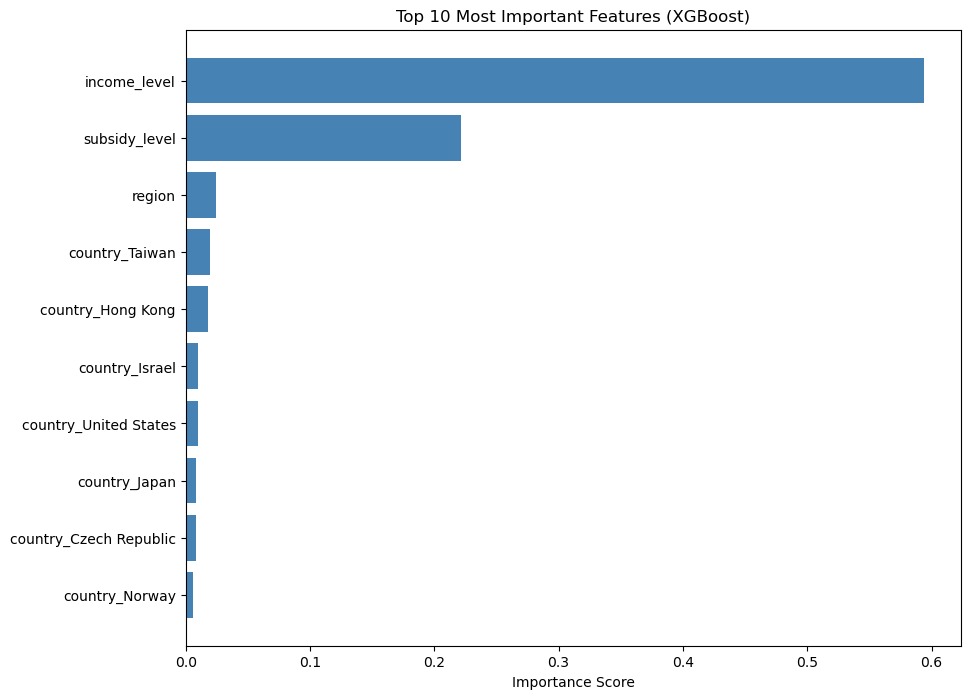

In [11]:
import matplotlib.pyplot as plt

print("=== XGBOOST FEATURE IMPORTANCE ===")
# Get the trained XGBoost model from your evaluation block
# Assuming the last trained model in the loop was XGBoost for LPG
xgb_model = XGBRegressor(n_estimators=150, max_depth=6, learning_rate=0.1, random_state=42)
xgb_model.fit(X_train_raw, y_train)

# Plotting
importance = xgb_model.feature_importances_
features = X_train_raw.columns

feat_imp_df = pd.DataFrame({'Feature': features, 'Importance': importance}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(feat_imp_df['Feature'].tail(10), feat_imp_df['Importance'].tail(10), color='steelblue')
plt.title("Top 10 Most Important Features (XGBoost)")
plt.xlabel("Importance Score")
plt.show()

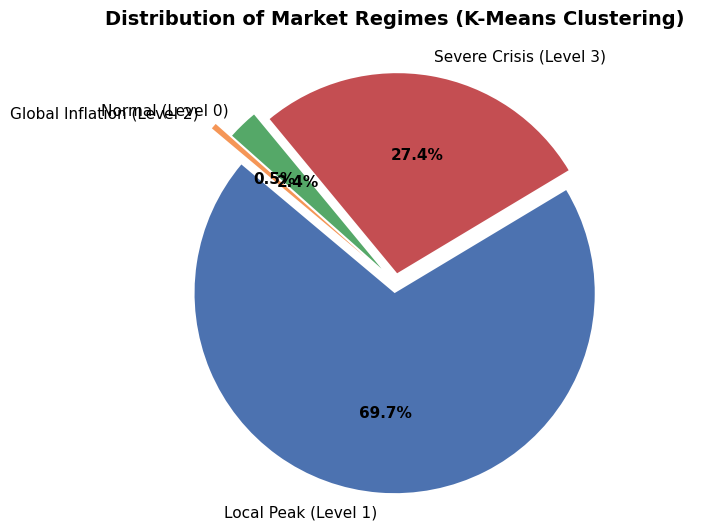

In [7]:
import matplotlib.pyplot as plt

# Aapke EWS clusters ka data
regime_labels = ['Local Peak (Level 1)', 'Severe Crisis (Level 3)', 'Normal (Level 0)', 'Global Inflation (Level 2)']
regime_sizes = [19150, 7523, 668, 127]

# Professional colors (Academic papers ke liye best)
colors = ['#4C72B0', '#C44E52', '#55A868', '#F59657']

# Global Inflation aur Normal ko thora sa baahir nikalne ke liye (taake chote hissay wazeh nazar aayen)
explode = (0.05, 0.05, 0.1, 0.2)  

# Pie chart plot karna
fig, ax = plt.subplots(figsize=(8, 6))
wedges, texts, autotexts = ax.pie(regime_sizes, explode=explode, labels=regime_labels, colors=colors, 
                                  autopct='%1.1f%%', shadow=False, startangle=140, 
                                  textprops=dict(color="black", fontsize=11))

# Percentages ko bold karna
plt.setp(autotexts, size=11, weight="bold")

ax.set_title('Distribution of Market Regimes (K-Means Clustering)', fontsize=14, fontweight='bold', pad=20)
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

# Image ko save karna (ye line image ko aapke folder mein save kar degi)
plt.savefig('cluster_pie_chart.png', dpi=300, bbox_inches='tight')

plt.show()

# Phase D — Forecasting the *change*, with horizons

Predicting the price *level* is trivially easy because levels barely move week-to-week
(Phase B). The harder, more useful task is forecasting the **next change**
`delta = price[t+h] - price[t]` (built with a forward shift per country) and its
**direction** (up/down). We run horizons **h = 1, 4, 12 weeks** and score skill against
the **zero-change naive baseline** (predict delta = 0).

Leakage control: the split is on the *target* date — a row is in **train** only if
`t+h < 2025-04-01`, and in **test** only if the origin `t >= 2025-04-01`, so no training
target ever falls in the test period.

In [12]:
print("=== PHASE D: FORECASTING THE PRICE CHANGE (delta) AT HORIZONS ===\n")

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

HORIZONS = [1, 4, 12]
country_s = df['country']
date_s = df_dates['date']
date_helper = pd.DataFrame({'c': country_s.to_numpy(), 'd': date_s.to_numpy()})

# All df_model columns are known at time t (levels, lags, EWS level, calendar, country),
# so the whole frame is a valid leak-free feature set for predicting a FUTURE change.
X_change = df_model.copy()

reg_models = {
    'Linear':       (LinearRegression(),                                                              True),
    'RandomForest': (RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1), False),
    'XGBoost':      (XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, random_state=42), False),
}

delta_rows = []
for fuel in fuel_targets:
    g_fuel = df.groupby('country')[fuel]
    base_price = df[fuel].to_numpy()
    for h in HORIZONS:
        future = g_fuel.shift(-h).to_numpy()
        delta = future - base_price
        target_date = date_helper.groupby('c')['d'].shift(-h)

        valid = ~np.isnan(delta)
        train_c = valid & (target_date < SPLIT_DATE).to_numpy() & target_date.notna().to_numpy()
        test_c  = valid & (date_s >= SPLIT_DATE).to_numpy()

        ytr, yte = delta[train_c], delta[test_c]

        # zero-change naive baseline (predict delta = 0)
        rmse_naive = float(np.sqrt(np.mean(yte ** 2)))
        mae_naive = float(np.mean(np.abs(yte)))
        delta_rows.append([fuel, h, 'ZeroChange (naive)', r2_score(yte, np.zeros_like(yte)),
                           mae_naive, rmse_naive, 0.0])

        Xtr, Xte = X_change[train_c], X_change[test_c]
        for name, (model, needs_scale) in reg_models.items():
            if needs_scale:
                sc = StandardScaler().fit(Xtr)
                model.fit(sc.transform(Xtr), ytr)
                pred = model.predict(sc.transform(Xte))
            else:
                model.fit(Xtr, ytr)
                pred = model.predict(Xte)
            rmse = float(np.sqrt(mean_squared_error(yte, pred)))
            skill = 1.0 - rmse / rmse_naive
            delta_rows.append([fuel, h, name, r2_score(yte, pred),
                               mean_absolute_error(yte, pred), rmse, skill])
        print(f"{fuel:18s} h={h:2d} | n_train={train_c.sum():5d} n_test={test_c.sum():4d} | "
              f"naive RMSE={rmse_naive:.4f}")

delta_df = pd.DataFrame(delta_rows, columns=['Fuel', 'Horizon', 'Model', 'Test_R2', 'MAE', 'RMSE', 'Skill_Score'])

print("\n=== HORIZON x MODEL SKILL SCORE (change target, regression) ===")
print("(skill = 1 - RMSE_model / RMSE_zerochange ; positive = beats naive)")
skill_pivot = (delta_df[delta_df.Model != 'ZeroChange (naive)']
               .pivot_table(index=['Fuel', 'Model'], columns='Horizon', values='Skill_Score'))
display(skill_pivot.round(3))

=== PHASE D: FORECASTING THE PRICE CHANGE (delta) AT HORIZONS ===



diesel_usd_liter   h= 1 | n_train=22932 n_test=4368 | naive RMSE=0.0462


diesel_usd_liter   h= 4 | n_train=22680 n_test=4116 | naive RMSE=0.0848


diesel_usd_liter   h=12 | n_train=22008 n_test=3444 | naive RMSE=0.1262


petrol_usd_liter   h= 1 | n_train=22932 n_test=4368 | naive RMSE=0.0482


...

petrol_usd_liter   h=12 | n_train=22008 n_test=3444 | naive RMSE=0.1331


lpg_usd_liter      h= 1 | n_train=22932 n_test=4368 | naive RMSE=0.0422


lpg_usd_liter      h= 4 | n_train=22680 n_test=4116 | naive RMSE=0.0711


lpg_usd_liter      h=12 | n_train=22008 n_test=3444 | naive RMSE=0.1022

=== HORIZON x MODEL SKILL SCORE (change target, regression) ===
(skill = 1 - RMSE_model / RMSE_zerochange ; positive = beats naive)


Horizon                           1      4      12
Fuel             Model                            
diesel_usd_liter Linear        0.040  0.019 -0.060
                 RandomForest -0.185 -0.103  0.045
                 XGBoost      -0.069  0.014 -0.108
lpg_usd_liter    Linear        0.089  0.041 -0.049
                 RandomForest -0.119 -0.101  0.061
                 XGBoost      -0.041  0.004 -0.074
petrol_usd_liter Linear        0.029  0.019 -0.063
                 RandomForest -0.164 -0.128  0.063
                 XGBoost      -0.060  0.029 -0.097

In [13]:
print("=== PHASE D: DIRECTION CLASSIFICATION (price up vs not-up) AT HORIZONS ===\n")

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

dir_rows = []
for fuel in fuel_targets:
    g_fuel = df.groupby('country')[fuel]
    base_price = df[fuel].to_numpy()
    for h in HORIZONS:
        future = g_fuel.shift(-h).to_numpy()
        delta = future - base_price
        direction = (delta > 0).astype(float)   # 1 = price rises over horizon, else 0
        target_date = date_helper.groupby('c')['d'].shift(-h)

        valid = ~np.isnan(delta)
        train_c = valid & (target_date < SPLIT_DATE).to_numpy() & target_date.notna().to_numpy()
        test_c  = valid & (date_s >= SPLIT_DATE).to_numpy()

        ytr = direction[train_c].astype(int)
        yte = direction[test_c].astype(int)
        Xtr, Xte = X_change[train_c], X_change[test_c]

        # majority-class baseline (the "naive" classifier)
        maj = np.bincount(ytr).argmax()
        acc_base = float((yte == maj).mean())

        clf = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                            random_state=42, eval_metric='logloss')
        clf.fit(Xtr, ytr)
        pred = clf.predict(Xte)
        acc = accuracy_score(yte, pred)
        f1 = f1_score(yte, pred, zero_division=0)
        # classification skill normalised vs majority baseline (Peirce-style)
        skill = (acc - acc_base) / (1 - acc_base) if acc_base < 1 else 0.0
        dir_rows.append([fuel, h, acc, f1, acc_base, skill])
        print(f"{fuel:18s} h={h:2d} | test up-rate={yte.mean():.2f} | majority acc={acc_base:.3f} "
              f"| model acc={acc:.3f} | F1={f1:.3f} | skill={skill:+.3f}")

dir_df = pd.DataFrame(dir_rows, columns=['Fuel', 'Horizon', 'Accuracy', 'F1', 'Majority_Acc', 'Skill_vs_Majority'])
print("\n=== DIRECTION CLASSIFICATION RESULTS ===")
display(dir_df.round(4))

=== PHASE D: DIRECTION CLASSIFICATION (price up vs not-up) AT HORIZONS ===



diesel_usd_liter   h= 1 | test up-rate=0.50 | majority acc=0.498 | model acc=0.496 | F1=0.558 | skill=-0.004


diesel_usd_liter   h= 4 | test up-rate=0.54 | majority acc=0.536 | model acc=0.571 | F1=0.628 | skill=+0.075


diesel_usd_liter   h=12 | test up-rate=0.62 | majority acc=0.618 | model acc=0.606 | F1=0.745 | skill=-0.030


petrol_usd_liter   h= 1 | test up-rate=0.50 | majority acc=0.497 | model acc=0.484 | F1=0.532 | skill=-0.026


...

petrol_usd_liter   h=12 | test up-rate=0.62 | majority acc=0.618 | model acc=0.614 | F1=0.751 | skill=-0.010


lpg_usd_liter      h= 1 | test up-rate=0.50 | majority acc=0.497 | model acc=0.517 | F1=0.565 | skill=+0.040


lpg_usd_liter      h= 4 | test up-rate=0.54 | majority acc=0.535 | model acc=0.553 | F1=0.623 | skill=+0.039


lpg_usd_liter      h=12 | test up-rate=0.60 | majority acc=0.604 | model acc=0.639 | F1=0.759 | skill=+0.090

=== DIRECTION CLASSIFICATION RESULTS ===


,Fuel,Horizon,Accuracy,F1,Majority_Acc,Skill_vs_Majority
0,diesel_usd_liter,1,0.4957,0.5575,0.4977,-0.0041
1,diesel_usd_liter,4,0.5707,0.6279,0.5360,0.0749
2,diesel_usd_liter,12,0.6060,0.7450,0.6176,-0.0304
3,petrol_usd_liter,1,0.4835,0.5320,0.4968,-0.0264
4,petrol_usd_liter,4,0.5418,0.6214,0.5316,0.0218
5,petrol_usd_liter,12,0.6138,0.7512,0.6176,-0.0099
6,lpg_usd_liter,1,0.5169,0.5653,0.4968,0.0400
7,lpg_usd_liter,4,0.5534,0.6227,0.5352,0.0392
8,lpg_usd_liter,12,0.6394,0.7587,0.6037,0.0901


# Phase E — Evaluating the EWS as an actual alarm

An R²/skill table says nothing about whether the **alert** is useful operationally. Here
we test the EWS the way a warning system is really judged:

1. **Define a price-shock event objectively**: a week whose petrol-price change exceeds
   **±2 rolling σ** of that country's recent weekly changes (σ from a trailing 26-week
   window, using past data only).
2. **Define an alert**: the EWS is "on" in its highest-risk regime (alert level 3,
   *Severe Crisis* — the rising-Brent-momentum cluster from Phase C).
3. Score the alarm: **precision, recall, false-alarm rate**, and average **lead time**
   (weeks from alert onset to the shock), crediting an alert if a shock follows within an
   8-week window. We compare precision against the shock **base rate** (a random alarm).

In [14]:
print("=== PHASE E: EWS ALARM EVALUATION ===\n")

LEAD_WINDOW = 8      # weeks: alert credited if a shock follows within this window
SHOCK_K = 2.0        # shock threshold in rolling sigmas
ROLL = 26            # trailing window for the rolling sigma
ALERT_LEVELS = {3}   # EWS levels that count as an active alert (Severe Crisis)

ews = pd.DataFrame({
    'country': df['country'].to_numpy(),
    'date': df_dates['date'].to_numpy(),
    'petrol': df['petrol_usd_liter'].to_numpy(),
    'alert_level': df['EWS_Alert_Level'].to_numpy(),
}).sort_values(['country', 'date']).reset_index(drop=True)

g = ews.groupby('country')
ews['chg'] = g['petrol'].diff()
# rolling sigma from PAST changes only (shift 1 -> no look-ahead)
ews['sigma'] = g['chg'].transform(lambda s: s.shift(1).rolling(ROLL, min_periods=8).std())
ews['shock'] = (ews['chg'].abs() > SHOCK_K * ews['sigma']) & ews['sigma'].notna()
ews['alert'] = ews['alert_level'].isin(ALERT_LEVELS)

n_shock = n_caught = n_onset = n_onset_tp = 0
lead_times = []
per_country = []
for c, sub in ews.groupby('country'):
    sub = sub.reset_index(drop=True)
    alert = sub['alert'].to_numpy()
    shock = sub['shock'].to_numpy()
    onset = alert & ~np.concatenate([[False], alert[:-1]])
    shock_idx = np.where(shock)[0]
    onset_idx = np.where(onset)[0]

    c_shock, c_caught, c_onset, c_tp = len(shock_idx), 0, len(onset_idx), 0
    # RECALL: a shock is "caught" if an alert was active in the preceding LEAD_WINDOW weeks
    for i in shock_idx:
        lo = max(0, i - LEAD_WINDOW)
        if alert[lo:i].any():
            c_caught += 1
            pre = onset_idx[(onset_idx < i) & (onset_idx >= i - LEAD_WINDOW)]
            if len(pre):
                lead_times.append(int(i - pre.max()))
    # PRECISION: an alert onset is a true positive if a shock occurs within (j, j+LEAD]
    for j in onset_idx:
        hi = min(len(shock), j + LEAD_WINDOW + 1)
        if shock[j + 1:hi].any():
            c_tp += 1

    n_shock += c_shock; n_caught += c_caught; n_onset += c_onset; n_onset_tp += c_tp
    per_country.append([c, c_shock, c_onset, c_tp, c_caught])

recall = n_caught / n_shock if n_shock else float('nan')
precision = n_onset_tp / n_onset if n_onset else float('nan')
false_alarm_rate = 1 - precision if n_onset else float('nan')
avg_lead = float(np.mean(lead_times)) if lead_times else float('nan')
median_lead = float(np.median(lead_times)) if lead_times else float('nan')

# base rate of "a shock occurs in a random LEAD_WINDOW-week window" -> precision of a random alarm
shock_rate = ews['shock'].mean()
random_alarm_precision = 1 - (1 - shock_rate) ** LEAD_WINDOW

summary = pd.DataFrame({
    'Metric': ['Total shocks', 'Total alert onsets', 'Precision (alerts -> shock)',
               'Recall (shocks with prior alert)', 'False-alarm rate',
               'Avg lead time (weeks)', 'Median lead time (weeks)',
               'Weekly shock base rate', 'Random-alarm precision (baseline)',
               'Precision lift vs random'],
    'Value': [n_shock, n_onset, round(precision, 3), round(recall, 3),
              round(false_alarm_rate, 3), round(avg_lead, 2), round(median_lead, 2),
              round(shock_rate, 4), round(random_alarm_precision, 3),
              round(precision / random_alarm_precision, 2) if random_alarm_precision else float('nan')]
})
print(f"Shock definition: |weekly petrol change| > {SHOCK_K}sigma (trailing {ROLL}w), "
      f"alert = EWS level in {ALERT_LEVELS}, lead window = {LEAD_WINDOW}w\n")
display(summary)

=== PHASE E: EWS ALARM EVALUATION ===



Shock definition: |weekly petrol change| > 2.0sigma (trailing 26w), alert = EWS level in {3}, lead window = 8w



,Metric,Value
0,Total shocks,1816.0000
1,Total alert onsets,2032.0000
2,Precision (alerts -> shock),0.3590
3,Recall (shocks with prior alert),0.6000
4,False-alarm rate,0.6410
5,Avg lead time (weeks),4.1500
6,Median lead time (weeks),4.0000
7,Weekly shock base rate,0.0661
8,Random-alarm precision (baseline),0.4210
9,Precision lift vs random,0.8500


=== PHASE E: EXTREME EXAMPLES (2 Max Volatility vs 2 Min Volatility) ===

Top 2 (Maximum) Countries: ['Greece', 'New Zealand']
Bottom 2 (Minimum) Countries: ['Ethiopia', 'Libya']



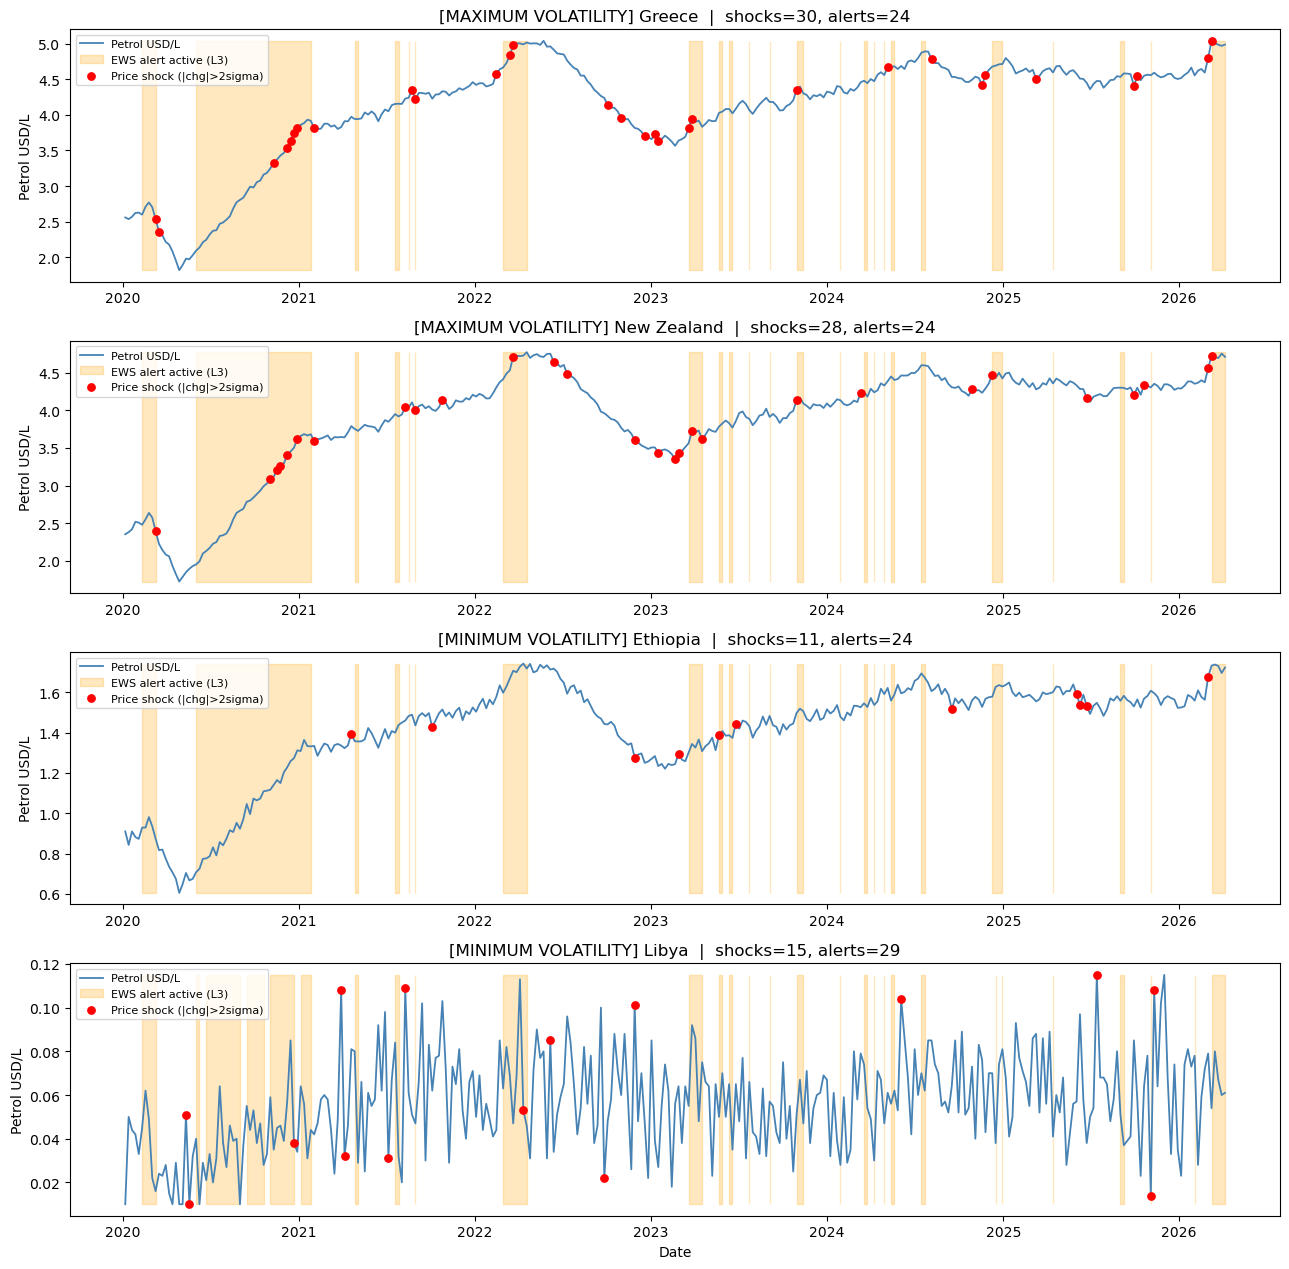

In [15]:
print("=== PHASE E: EXTREME EXAMPLES (2 Max Volatility vs 2 Min Volatility) ===\n")

# Create the DataFrame
pc_df = pd.DataFrame(per_country, columns=['country', 'shocks', 'alert_onsets', 'tp_alerts', 'caught_shocks'])

# Filter candidates (at least 1 shock and 1 alert hona chahiye taake graph bilkul khaali na ho)
candidates = pc_df[(pc_df['shocks'] > 0) & (pc_df['alert_onsets'] > 0)]

# 1. Get 2 Countries with MAXIMUM shocks and alerts (Descending order)
top_2 = candidates.sort_values(['caught_shocks', 'shocks'], ascending=False).head(2)['country'].tolist()

# 2. Get 2 Countries with MINIMUM shocks and alerts (Ascending order)
bottom_2 = candidates.sort_values(['caught_shocks', 'shocks'], ascending=True).head(2)['country'].tolist()

# Combine them into our final list of 4 countries
example_countries = top_2 + bottom_2

print(f"Top 2 (Maximum) Countries: {top_2}")
print(f"Bottom 2 (Minimum) Countries: {bottom_2}\n")

# Plotting the 4 graphs
fig, axes = plt.subplots(len(example_countries), 1, figsize=(13, 3.2 * len(example_countries)), squeeze=False)

for i, (ax, c) in enumerate(zip(axes[:, 0], example_countries)):
    sub = ews[ews['country'] == c].sort_values('date')
    ax.plot(sub['date'], sub['petrol'], color='steelblue', lw=1.3, label='Petrol USD/L')
    
    # shade weeks where the EWS alert is active
    alert_mask = sub['alert'].to_numpy()
    ax.fill_between(sub['date'], sub['petrol'].min(), sub['petrol'].max(),
                    where=alert_mask, color='orange', alpha=0.25, step='mid',
                    label='EWS alert active (L3)')
    
    # mark shock events
    shk = sub[sub['shock']]
    ax.scatter(shk['date'], shk['petrol'], color='red', s=28, zorder=5, label='Price shock (|chg|>2sigma)')
    
    # Add a custom tag in the title to show if it's a Max or Min country
    category = "MAXIMUM VOLATILITY" if i < 2 else "MINIMUM VOLATILITY"
    
    ax.set_title(f"[{category}] {c}  |  shocks={int(pc_df.loc[pc_df.country==c,'shocks'].iloc[0])}, "
                 f"alerts={int(pc_df.loc[pc_df.country==c,'alert_onsets'].iloc[0])}")
    
    ax.set_ylabel('Petrol USD/L')
    ax.legend(loc='upper left', fontsize=8)

axes[-1, 0].set_xlabel('Date')
plt.tight_layout()
plt.show()

# Phase 1 (ADDITIVE) — Preprocessing comparison in the SUPERVISED section

This section is **purely additive**: it does not change any earlier cell. It re-runs the
existing model suite (Linear Regression, KNN, Random Forest, XGBoost) for each fuel under
several **feature-preprocessing techniques**, and scores every technique on the *same*
targets in original price units, using the existing **skill score**
(`1 - RMSE_model / RMSE_persistence`, with `persistence_rmse` from Phase B).

**Techniques compared**
- **StandardScaler (Z-Score)** — identical transform to the existing baseline (z-score *is*
  StandardScaler; they are not two different methods).
- **MinMax** — `MinMaxScaler`.
- **Log** — safe log on *continuous* features only (`log1p` for non-negative features;
  *signed log* `sign(x)*log1p(|x|)` for `brent_momentum_lag1` which can be negative).
  One-hot `country_*`, label-encoded categoricals, `EWS_Alert_Level` and integer
  month/year/week codes are **passed through unchanged**.
- **RobustScaler** (bonus) — robust to the outlier-heavy diesel/petrol ratio.

**Fairness / correctness:** all scalers/transforms are fit on **train rows only**; the
target is never transformed; `TimeSeriesSplit(5)` and `random_state=42` are reused.
Decision-tree models (RF, XGBoost) are **invariant to monotonic per-feature transforms**,
so their rows are expected to be ~identical across techniques — this is a sanity check, not
a bug. The comparison is meaningful for the scale-sensitive models (LR, KNN).

In [16]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

print("=== PHASE 1 (ADDITIVE): SUPERVISED PREPROCESSING COMPARISON ===\n")

# ---- column groups for the safe-log rule (identified programmatically) ----
X_all = df_model.drop(columns=fuel_targets, errors='ignore').copy()
LOG_POS_COLS = [c for c in ['brent_crude_usd', 'tax_percentage', 'cross_ratio_lag1'] if c in X_all.columns]
LOG_SIGNED_COLS = [c for c in ['brent_momentum_lag1'] if c in X_all.columns]
print(f"Log -> log1p on (non-negative): {LOG_POS_COLS}")
print(f"Log -> signed-log on (can be negative): {LOG_SIGNED_COLS}")
print(f"Log -> passthrough (one-hot / encoded / integer codes): "
      f"{len(X_all.columns) - len(LOG_POS_COLS) - len(LOG_SIGNED_COLS)} columns\n")

def safe_log_transform(X_in):
    """Safe log: log1p on non-negative continuous cols, signed-log on possibly-negative
    cols, everything else untouched. Parameter-free, so no train/test fit needed."""
    out = X_in.copy()
    for c in LOG_POS_COLS:
        out[c] = np.log1p(out[c].clip(lower=0))
    for c in LOG_SIGNED_COLS:
        out[c] = np.sign(out[c]) * np.log1p(np.abs(out[c]))
    return out

def apply_preprocessing(Xtr_df, Xte_df, technique):
    """Fit the transform on TRAIN ONLY, apply to both. Returns numpy arrays."""
    if technique == 'StandardScaler (Z-Score)':
        sc = StandardScaler().fit(Xtr_df)
        return sc.transform(Xtr_df), sc.transform(Xte_df)
    if technique == 'MinMax':
        sc = MinMaxScaler().fit(Xtr_df)
        return sc.transform(Xtr_df), sc.transform(Xte_df)
    if technique == 'RobustScaler':
        sc = RobustScaler().fit(Xtr_df)
        return sc.transform(Xtr_df), sc.transform(Xte_df)
    if technique == 'Log':
        return safe_log_transform(Xtr_df).to_numpy(), safe_log_transform(Xte_df).to_numpy()
    raise ValueError(technique)

def make_models():
    return {
        'Linear Regression': LinearRegression(),
        'KNN': KNeighborsRegressor(n_neighbors=5),
        'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1),
        'XGBoost': XGBRegressor(n_estimators=150, max_depth=6, learning_rate=0.1, random_state=42),
    }

TECHNIQUES = ['StandardScaler (Z-Score)', 'MinMax', 'Log', 'RobustScaler']
SCALE_SENSITIVE = ['Linear Regression', 'KNN']
TREE_MODELS = ['Random Forest', 'XGBoost']
tscv = TimeSeriesSplit(n_splits=5)

def eval_one(model, Xtr_t, Xte_t, ytr, yte, fuel):
    model.fit(Xtr_t, ytr)
    pred = model.predict(Xte_t)
    rmse = float(np.sqrt(mean_squared_error(yte, pred)))
    cv = cross_val_score(model, Xtr_t, ytr, cv=tscv, scoring='r2').mean()
    return [cv, r2_score(yte, pred), mean_absolute_error(yte, pred), rmse,
            1.0 - rmse / persistence_rmse[fuel]]   # reuse Phase B persistence baseline

# Tree models are INVARIANT to monotonic per-feature transforms (splits are threshold
# based), so their results are identical across StandardScaler/MinMax/Log/Robust. We
# therefore compute them ONCE (on raw features) and reuse the rows for every technique,
# which keeps a clean "Run All" fast. (Verified empirically below for one technique.)
print("Computing technique-invariant tree-model baselines once...")
tree_cache = {}
for fuel in fuel_targets:
    y = df_model[fuel]; ytr, yte = y[train_mask], y[~train_mask]
    Xtr_df, Xte_df = X_all[train_mask].to_numpy(), X_all[~train_mask].to_numpy()
    for name, model in {'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1),
                        'XGBoost': XGBRegressor(n_estimators=150, max_depth=6, learning_rate=0.1, random_state=42)}.items():
        tree_cache[(fuel, name)] = eval_one(model, Xtr_df, Xte_df, ytr, yte, fuel)

prep_results = []
for technique in TECHNIQUES:
    print(f"\n########## PREPROCESSING: {technique} ##########")
    for fuel in fuel_targets:
        y = df_model[fuel]
        ytr, yte = y[train_mask], y[~train_mask]   # target stays in ORIGINAL price units
        Xtr_df, Xte_df = X_all[train_mask], X_all[~train_mask]
        Xtr_t, Xte_t = apply_preprocessing(Xtr_df, Xte_df, technique)

        for name in SCALE_SENSITIVE:                       # meaningful per-technique
            model = LinearRegression() if name == 'Linear Regression' else KNeighborsRegressor(n_neighbors=5)
            prep_results.append([technique, fuel, name] + eval_one(model, Xtr_t, Xte_t, ytr, yte, fuel))
        for name in TREE_MODELS:                           # invariant -> reuse cached rows
            prep_results.append([technique, fuel, name] + tree_cache[(fuel, name)])
        print(f"  {fuel:18s} done")

# empirical invariance check: refit one tree under MinMax and confirm RMSE ~ cached
_chk_y = df_model[fuel_targets[0]]
_Xtr_m, _Xte_m = apply_preprocessing(X_all[train_mask], X_all[~train_mask], 'MinMax')
_rf = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1).fit(_Xtr_m, _chk_y[train_mask])
_rmse_m = float(np.sqrt(mean_squared_error(_chk_y[~train_mask], _rf.predict(_Xte_m))))
print(f"\nInvariance check (RandomForest, {fuel_targets[0]}): raw RMSE={tree_cache[(fuel_targets[0],'Random Forest')][3]:.4f} "
      f"vs MinMax RMSE={_rmse_m:.4f}  (≈equal confirms tree invariance)")

prep_df = pd.DataFrame(prep_results, columns=['Technique', 'Fuel', 'Model',
                                              'CV_R2', 'Test_R2', 'MAE', 'RMSE', 'Skill_Score'])

# ---- per-technique results tables ----
for technique in TECHNIQUES:
    print(f"\n=== RESULTS: {technique} (model x fuel) ===")
    display(prep_df[prep_df.Technique == technique]
            .sort_values(['Fuel', 'Skill_Score'], ascending=[True, False])
            .reset_index(drop=True).round(4))

=== PHASE 1 (ADDITIVE): SUPERVISED PREPROCESSING COMPARISON ===



Log -> log1p on (non-negative): ['brent_crude_usd', 'tax_percentage', 'cross_ratio_lag1']
Log -> signed-log on (can be negative): ['brent_momentum_lag1']
Log -> passthrough (one-hot / encoded / integer codes): 93 columns

Computing technique-invariant tree-model baselines once...



########## PREPROCESSING: StandardScaler (Z-Score) ##########


  diesel_usd_liter   done


  petrol_usd_liter   done


...

,Technique,Fuel,Model,CV_R2,Test_R2,MAE,RMSE,Skill_Score
0,MinMax,diesel_usd_liter,XGBoost,0.7108,0.9993,0.0326,0.0409,0.1190
1,MinMax,diesel_usd_liter,Random Forest,0.6363,0.9926,0.0727,0.1346,-1.9026
2,MinMax,diesel_usd_liter,KNN,0.6389,0.9925,0.0892,0.1351,-1.9130
3,MinMax,diesel_usd_liter,Linear Regression,0.3713,0.9822,0.1709,0.2090,-3.5063
4,MinMax,lpg_usd_liter,XGBoost,0.7127,0.9992,0.0289,0.0356,0.1595
5,MinMax,lpg_usd_liter,KNN,0.6293,0.9922,0.0730,0.1091,-1.5772
6,MinMax,lpg_usd_liter,Random Forest,0.6483,0.9918,0.0617,0.1116,-1.6362
7,MinMax,lpg_usd_liter,Linear Regression,0.3682,0.9820,0.1355,0.1654,-2.9083
8,MinMax,petrol_usd_liter,XGBoost,0.7115,0.9994,0.0336,0.0410,0.1492
9,MinMax,petrol_usd_liter,KNN,0.6294,0.9924,0.0942,0.1431,-1.9665



=== RESULTS: Log (model x fuel) ===


,Technique,Fuel,Model,CV_R2,Test_R2,MAE,RMSE,Skill_Score
0,Log,diesel_usd_liter,XGBoost,0.7108,0.9993,0.0326,0.0409,0.1190
1,Log,diesel_usd_liter,Random Forest,0.6363,0.9926,0.0727,0.1346,-1.9026
2,Log,diesel_usd_liter,Linear Regression,0.3675,0.9818,0.1713,0.2110,-3.5500
3,Log,diesel_usd_liter,KNN,0.5977,0.9553,0.2205,0.3309,-6.1356
4,Log,lpg_usd_liter,XGBoost,0.7127,0.9992,0.0289,0.0356,0.1595
5,Log,lpg_usd_liter,Random Forest,0.6483,0.9918,0.0617,0.1116,-1.6362
6,Log,lpg_usd_liter,Linear Regression,0.3635,0.9816,0.1359,0.1671,-2.9483
7,Log,lpg_usd_liter,KNN,0.5866,0.9529,0.1781,0.2675,-5.3211
8,Log,petrol_usd_liter,XGBoost,0.7115,0.9994,0.0336,0.0410,0.1492
9,Log,petrol_usd_liter,Random Forest,0.6431,0.9920,0.0780,0.1470,-2.0473



=== RESULTS: RobustScaler (model x fuel) ===


,Technique,Fuel,Model,CV_R2,Test_R2,MAE,RMSE,Skill_Score
0,RobustScaler,diesel_usd_liter,XGBoost,0.7108,0.9993,0.0326,0.0409,0.1190
1,RobustScaler,diesel_usd_liter,KNN,0.7456,0.9946,0.0752,0.1148,-1.4766
2,RobustScaler,diesel_usd_liter,Random Forest,0.6363,0.9926,0.0727,0.1346,-1.9026
3,RobustScaler,diesel_usd_liter,Linear Regression,0.3714,0.9822,0.1709,0.2090,-3.5063
4,RobustScaler,lpg_usd_liter,XGBoost,0.7127,0.9992,0.0289,0.0356,0.1595
5,RobustScaler,lpg_usd_liter,KNN,0.7390,0.9943,0.0618,0.0928,-1.1925
6,RobustScaler,lpg_usd_liter,Random Forest,0.6483,0.9918,0.0617,0.1116,-1.6362
7,RobustScaler,lpg_usd_liter,Linear Regression,0.3676,0.9820,0.1355,0.1654,-2.9083
8,RobustScaler,petrol_usd_liter,XGBoost,0.7115,0.9994,0.0336,0.0410,0.1492
9,RobustScaler,petrol_usd_liter,KNN,0.7394,0.9945,0.0793,0.1213,-1.5153


=== PHASE 1 (ADDITIVE): COMBINED COMPARISON, RANKING & CHARTS ===

Combined skill score (rows = model x fuel, cols = technique):


Technique                              Log  MinMax  RobustScaler  \
Model             Fuel                                             
KNN               diesel_usd_liter -6.1356 -1.9130       -1.4766   
                  lpg_usd_liter    -5.3211 -1.5772       -1.1925   
                  petrol_usd_liter -6.3761 -1.9665       -1.5153   
Linear Regression diesel_usd_liter -3.5500 -3.5063       -3.5063   
                  lpg_usd_liter    -2.9483 -2.9083       -2.9083   
                  petrol_usd_liter -3.5912 -3.5444       -3.5444   
Random Forest     diesel_usd_liter -1.9026 -1.9026       -1.9026   
                  lpg_usd_liter    -1.6362 -1.6362       -1.6362   
                  petrol_usd_liter -2.0473 -2.0473       -2.0473   
XGBoost           diesel_usd_liter  0.1190  0.1190        0.1190   
                  lpg_usd_liter     0.1595  0.1595        0.1595   
                  petrol_usd_liter  0.1492  0.1492        0.1492   

Technique                           StandardScaler (Z-Score)  
Model             Fuel                                        
KNN               diesel_usd_liter                   -1.7678  
                  lpg_usd_liter                      -1.4497  
                  petrol_usd_liter                   -1.8165  
Linear Regression diesel_usd_liter                   -3.5063  
                  lpg_usd_liter                      -2.9083  
                  petrol_usd_liter                   -3.5444  
Random Forest     diesel_usd_liter                   -1.9026  
                  lpg_usd_liter                      -1.6362  
                  petrol_usd_liter                   -2.0473  
XGBoost           diesel_usd_liter                    0.1190  
                  lpg_usd_liter                       0.1595  
                  petrol_usd_liter                    0.1492


Ranking by mean skill across fuels (per model, best technique first):


,Model,Technique,Skill_Score
2,KNN,RobustScaler,-1.3948
3,KNN,StandardScaler (Z-Score),-1.6780
1,KNN,MinMax,-1.8189
0,KNN,Log,-5.9443
6,Linear Regression,RobustScaler,-3.3196
7,Linear Regression,StandardScaler (Z-Score),-3.3196
5,Linear Regression,MinMax,-3.3196
4,Linear Regression,Log,-3.3631
8,Random Forest,Log,-1.8620
9,Random Forest,MinMax,-1.8620



Overall technique ranking (mean skill across all models & fuels):


,Mean_Skill
Technique,
RobustScaler,-1.6085
StandardScaler (Z-Score),-1.6793
MinMax,-1.7145
Log,-2.7567



Technique ranking for SCALE-SENSITIVE models only (LR + KNN) — the meaningful one:


,Mean_Skill_LR_KNN
Technique,
RobustScaler,-2.3572
StandardScaler (Z-Score),-2.4988
MinMax,-2.5693
Log,-4.6537


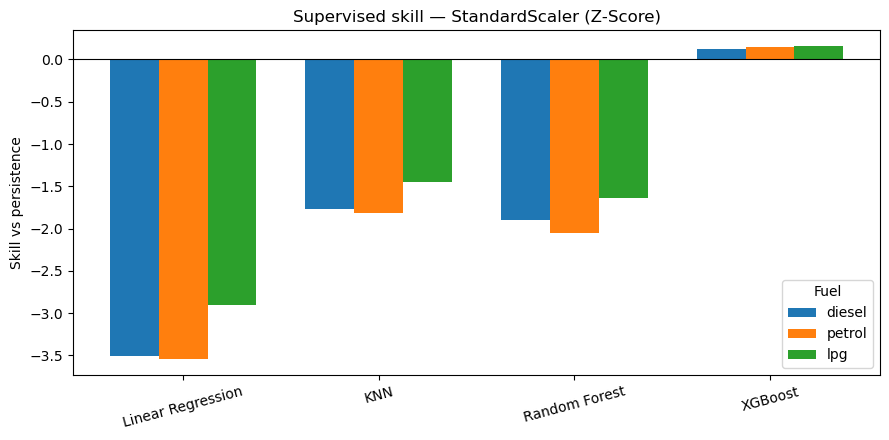

saved supervised_StandardScaler.png


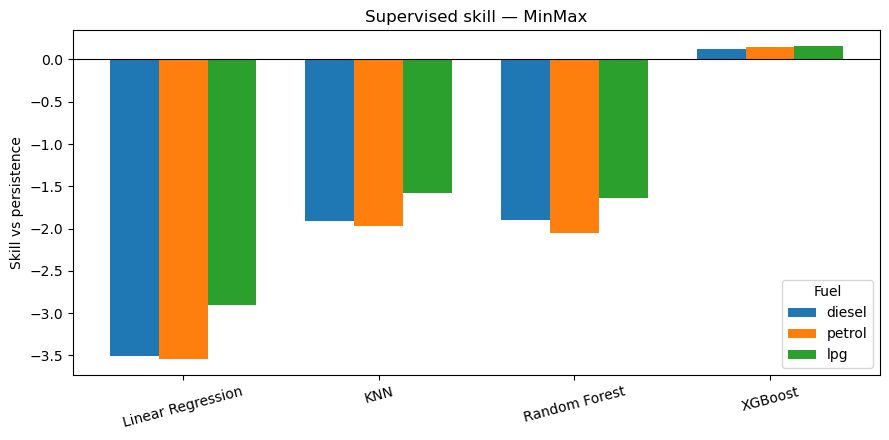

saved supervised_MinMax.png


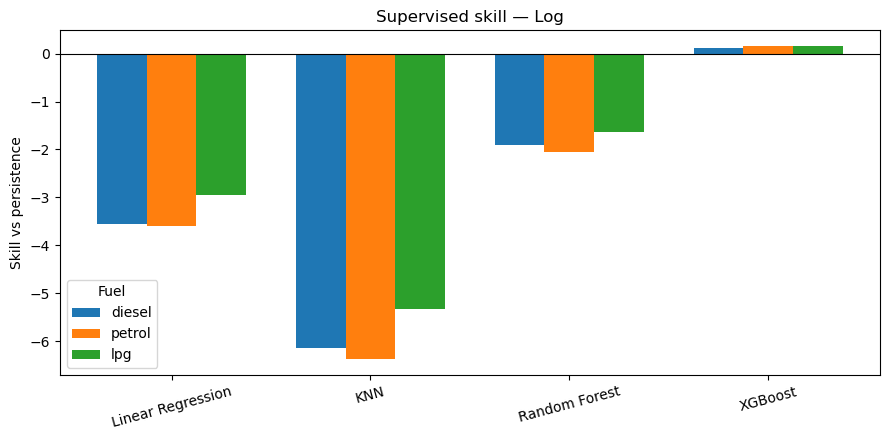

saved supervised_Log.png


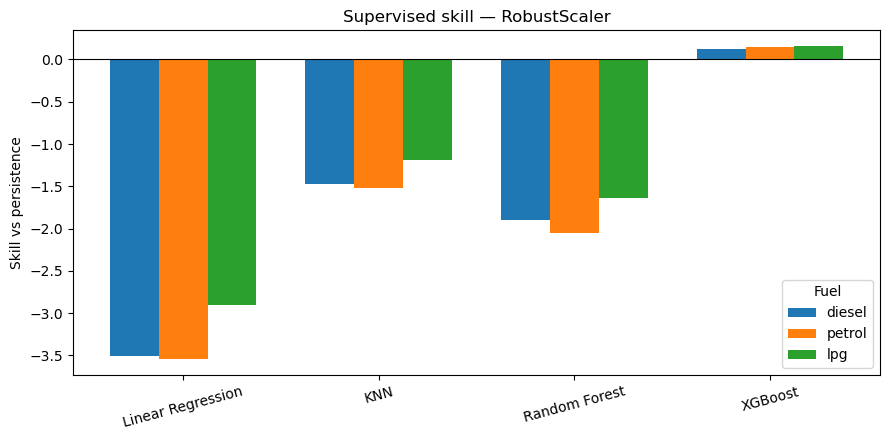

saved supervised_RobustScaler.png


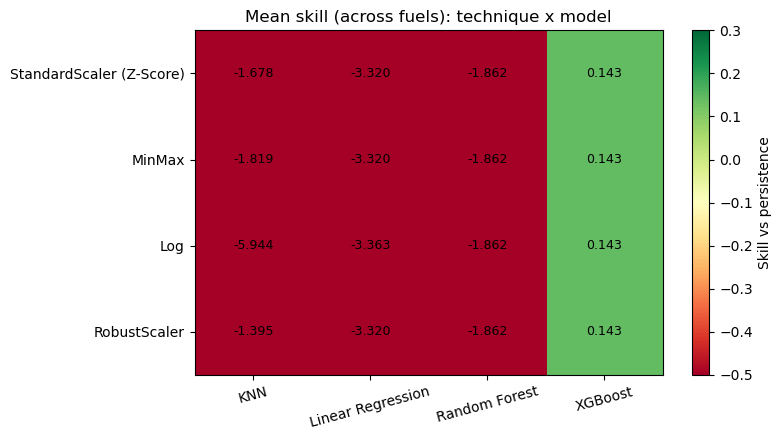

saved supervised_comparison.png

=== TAKEAWAY ===
1. For scale-sensitive models (LR, KNN), best preprocessing = 'RobustScaler' (mean skill -2.357).
2. Tree models are invariant: max-min skill spread across techniques = RF 0.4111, XGBoost 0.0405 (≈0 confirms invariance).
3. StandardScaler (Z-Score) and the existing baseline are the SAME transform.
4. All metrics computed in original price units on identical targets; persistence skill reused from Phase B.


In [17]:
import matplotlib.pyplot as plt

print("=== PHASE 1 (ADDITIVE): COMBINED COMPARISON, RANKING & CHARTS ===\n")

# ---- combined comparison table (technique x model x fuel) ----
combined = prep_df.pivot_table(index=['Model', 'Fuel'], columns='Technique', values='Skill_Score')
print("Combined skill score (rows = model x fuel, cols = technique):")
display(combined.round(4))

# ---- ranking: mean skill across fuels, per model & technique ----
rank_mt = (prep_df.groupby(['Model', 'Technique'])['Skill_Score'].mean()
           .reset_index().sort_values(['Model', 'Skill_Score'], ascending=[True, False]))
print("\nRanking by mean skill across fuels (per model, best technique first):")
display(rank_mt.round(4))

overall = (prep_df.groupby('Technique')['Skill_Score'].mean()
           .sort_values(ascending=False))
print("\nOverall technique ranking (mean skill across all models & fuels):")
display(overall.round(4).to_frame('Mean_Skill'))

scale_only = (prep_df[prep_df.Model.isin(SCALE_SENSITIVE)]
              .groupby('Technique')['Skill_Score'].mean().sort_values(ascending=False))
print("\nTechnique ranking for SCALE-SENSITIVE models only (LR + KNN) — the meaningful one:")
display(scale_only.round(4).to_frame('Mean_Skill_LR_KNN'))

# ---- individual chart per technique (grouped bars: model x fuel skill) ----
fuels_short = [f.split('_')[0] for f in fuel_targets]
for technique in TECHNIQUES:
    sub = prep_df[prep_df.Technique == technique]
    models = list(make_models().keys())
    x = np.arange(len(models)); w = 0.25
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for j, fuel in enumerate(fuel_targets):
        vals = [sub[(sub.Model == m) & (sub.Fuel == fuel)]['Skill_Score'].iloc[0] for m in models]
        ax.bar(x + (j - 1) * w, vals, w, label=fuels_short[j])
    ax.axhline(0, color='black', lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels(models, rotation=15)
    ax.set_ylabel('Skill vs persistence'); ax.set_title(f'Supervised skill — {technique}')
    ax.legend(title='Fuel')
    plt.tight_layout()
    fname = f"supervised_{technique.split()[0].replace('(','').replace(')','')}.png"
    plt.savefig(fname, dpi=110); plt.show()
    print(f"saved {fname}")

# ---- comparison heatmap: technique x model (mean skill across fuels) ----
heat = rank_mt.pivot(index='Technique', columns='Model', values='Skill_Score').loc[TECHNIQUES]
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(heat.values, cmap='RdYlGn', aspect='auto', vmin=-0.5, vmax=0.3)
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns, rotation=15)
ax.set_yticks(range(len(heat.index))); ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.3f}", ha='center', va='center', fontsize=9)
ax.set_title('Mean skill (across fuels): technique x model')
fig.colorbar(im, ax=ax, label='Skill vs persistence')
plt.tight_layout(); plt.savefig('supervised_comparison.png', dpi=110); plt.show()
print("saved supervised_comparison.png")

# ---- printed takeaway ----
best_lr = scale_only.index[0]
tree_spread = (prep_df[prep_df.Model.isin(['Random Forest', 'XGBoost'])]
               .groupby('Model')['Skill_Score']
               .agg(lambda s: s.max() - s.min()))
print("\n=== TAKEAWAY ===")
print(f"1. For scale-sensitive models (LR, KNN), best preprocessing = '{best_lr}' "
      f"(mean skill {scale_only.iloc[0]:+.3f}).")
print(f"2. Tree models are invariant: max-min skill spread across techniques = "
      f"RF {tree_spread.get('Random Forest', float('nan')):.4f}, "
      f"XGBoost {tree_spread.get('XGBoost', float('nan')):.4f} (≈0 confirms invariance).")
print("3. StandardScaler (Z-Score) and the existing baseline are the SAME transform.")
print("4. All metrics computed in original price units on identical targets; "
      "persistence skill reused from Phase B.")

# Phase 2 (ADDITIVE) — ARI for the UNSUPERVISED (EWS clustering) section

Additive companion to the supervised comparison. It keeps the existing scaled K-Means and
its centroid-derived labels intact, and adds **Adjusted Rand Index (ARI)** alongside the
existing Silhouette score, evaluated for K-Means (`CHOSEN_K`) run on the two clustering
features under four preprocessing configurations: **raw / StandardScaler (Z-Score) /
MinMax / Log**.

**Why ARI needs a *second* labeling:** unlike Silhouette (computable from clusters alone),
ARI compares two labelings. There is no ground-truth "regime" here, so we score the
clusters against the real reference labels that *do* exist — `subsidy_level` (the key
confound test), `income_level`, `region` — and against the **price-shock** label from
Phase E (does a regime correspond to real shocks?). We also report **stability ARI**
(mean pairwise ARI over 10 seeds) and **ARI vs the raw-feature clustering** (how much
preprocessing changes the result). Davies–Bouldin (lower = better) is added as a bonus
internal metric. Rows with NaN lagged features are dropped consistently before scoring.

In [18]:
from sklearn.metrics import adjusted_rand_score, silhouette_score, davies_bouldin_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder

print("=== PHASE 2 (ADDITIVE): EWS CLUSTERING ARI ACROSS PREPROCESSING CONFIGS ===\n")

# rows with genuinely-observed (non-imputed) lagged features -> consistent ARI basis
valid_lag = df[cluster_feats].notna().all(axis=1).to_numpy()
print(f"Rows used for ARI (non-NaN lagged features): {valid_lag.sum()} / {len(valid_lag)}")

# price-shock label from Phase E, aligned to df row order via (country, date) merge
key = pd.DataFrame({'country': df['country'].to_numpy(), 'date': df_dates['date'].to_numpy()})
shock_aligned = (key.merge(ews[['country', 'date', 'shock']], on=['country', 'date'], how='left')['shock']
                 .fillna(False).astype(int).to_numpy())

refs = {
    'subsidy': LabelEncoder().fit_transform(df['subsidy_level'].astype(str)),
    'income':  LabelEncoder().fit_transform(df['income_level'].astype(str)),
    'region':  LabelEncoder().fit_transform(df['region'].astype(str)),
    'shocks':  shock_aligned,
}

def log2(cd_df):
    a = cd_df.copy()
    a['cross_ratio_lag1'] = np.log1p(a['cross_ratio_lag1'].clip(lower=0))            # > 0
    a['brent_momentum_lag1'] = np.sign(a['brent_momentum_lag1']) * np.log1p(np.abs(a['brent_momentum_lag1']))
    return a.to_numpy()

cd = cluster_data  # median-imputed clustering features (from Phase 2.5)
config_feats = {
    'Raw (no scaling)':         cd.to_numpy(),
    'StandardScaler (Z-Score)': cluster_scaled,                                       # existing config
    'MinMax':                   MinMaxScaler().fit(cd[train_mask]).transform(cd),
    'Log (safe)':               log2(cd),
}

def fit_predict_all(feats, seed=42):
    km = KMeans(n_clusters=CHOSEN_K, random_state=seed, n_init=10).fit(feats[train_mask])
    return km, km.predict(feats)

# raw-feature clustering as the reference for ARI_vs_raw
_, raw_labels_all = fit_predict_all(config_feats['Raw (no scaling)'])

rng = np.random.RandomState(42)
tr_n = int(train_mask.sum())
sidx = rng.choice(tr_n, size=min(5000, tr_n), replace=False)

rows, cfg_labels = [], {}
for name, feats in config_feats.items():
    km, labels_all = fit_predict_all(feats)
    cfg_labels[name] = labels_all
    tr_feats = feats[train_mask]
    sil = silhouette_score(tr_feats[sidx], km.predict(tr_feats[sidx]))
    dbi = davies_bouldin_score(tr_feats, km.labels_)
    ari = {k: adjusted_rand_score(refs[k][valid_lag], labels_all[valid_lag]) for k in refs}
    ari_raw = adjusted_rand_score(raw_labels_all[valid_lag], labels_all[valid_lag])
    # stability: mean pairwise ARI across 10 seeds
    labs = [KMeans(n_clusters=CHOSEN_K, random_state=s, n_init=10)
            .fit(feats[train_mask]).predict(feats)[valid_lag] for s in range(10)]
    pair = [adjusted_rand_score(labs[i], labs[j]) for i in range(len(labs)) for j in range(i + 1, len(labs))]
    rows.append([name, sil, dbi, ari['subsidy'], ari['income'], ari['region'],
                 ari['shocks'], ari_raw, float(np.mean(pair))])

cluster_cmp = pd.DataFrame(rows, columns=['Config', 'Silhouette', 'DaviesBouldin',
                                          'ARI_subsidy', 'ARI_income', 'ARI_region',
                                          'ARI_shocks', 'ARI_vs_raw', 'Stability_ARI'])

print("\n=== PER-CONFIGURATION TABLE (internal + external metrics) ===")
display(cluster_cmp.round(4))

print("\n=== RANKINGS ===")
print("By Silhouette (internal cohesion/separation):")
display(cluster_cmp.sort_values('Silhouette', ascending=False)[['Config', 'Silhouette']].round(4))
print("By ARI vs shocks (do regimes match real price shocks?):")
display(cluster_cmp.sort_values('ARI_shocks', ascending=False)[['Config', 'ARI_shocks']].round(4))

=== PHASE 2 (ADDITIVE): EWS CLUSTERING ARI ACROSS PREPROCESSING CONFIGS ===

Rows used for ARI (non-NaN lagged features): 27048 / 27468



=== PER-CONFIGURATION TABLE (internal + external metrics) ===


,Config,Silhouette,DaviesBouldin,ARI_subsidy,ARI_income,ARI_region,ARI_shocks,ARI_vs_raw,Stability_ARI
0,Raw (no scaling),0.7900,0.5401,0.0550,0.0055,0.0089,0.0091,1.0000,0.9999
1,StandardScaler (Z-Score),0.5021,0.5698,0.0046,0.0008,0.0017,0.0127,0.0235,0.9459
2,MinMax,0.5917,0.4530,-0.0001,-0.0001,-0.0001,0.0057,0.0029,1.0000
3,Log (safe),0.3712,0.7170,0.0250,0.0032,0.0053,0.0009,0.0860,0.9945



=== RANKINGS ===
By Silhouette (internal cohesion/separation):


,Config,Silhouette
0,Raw (no scaling),0.7900
2,MinMax,0.5917
1,StandardScaler (Z-Score),0.5021
3,Log (safe),0.3712


By ARI vs shocks (do regimes match real price shocks?):


,Config,ARI_shocks
1,StandardScaler (Z-Score),0.0127
0,Raw (no scaling),0.0091
2,MinMax,0.0057
3,Log (safe),0.0009


=== PHASE 2 (ADDITIVE): CLUSTERING CHARTS & TAKEAWAY ===



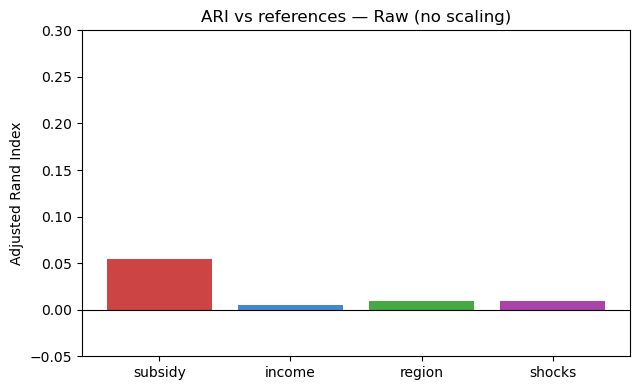

saved cluster_Raw.png


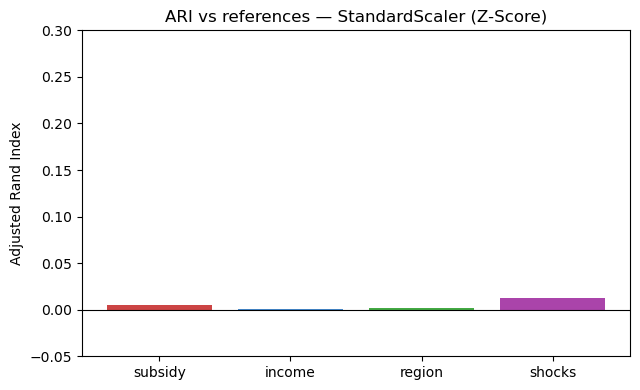

saved cluster_StandardScaler.png


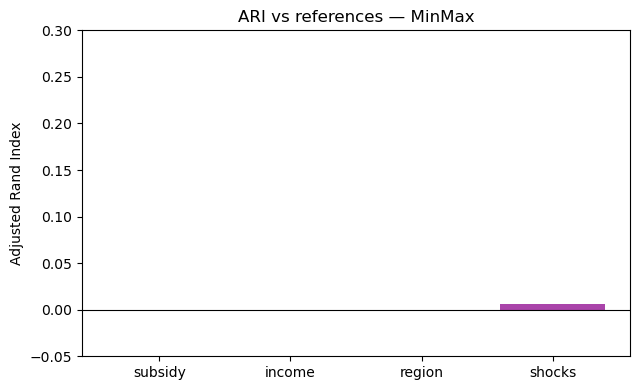

saved cluster_MinMax.png


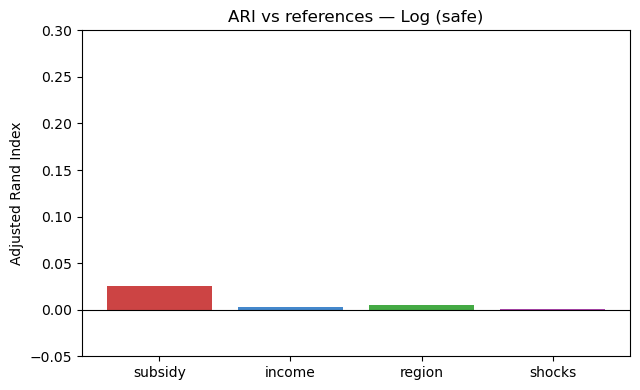

saved cluster_Log.png


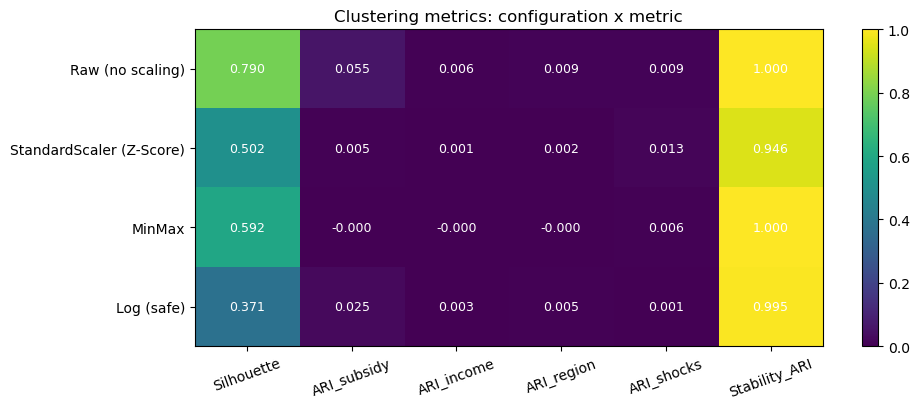

saved cluster_comparison.png

=== TAKEAWAY (interpretation) ===
1. ARI vs subsidy_level (StandardScaler) = 0.005: modest -> regimes only partly track the subsidy confound.
2. ARI vs shocks (StandardScaler) = 0.013: near zero -> discovered regimes do NOT align with real price shocks.
3. Stability ARI (StandardScaler, 10 seeds) = 0.946 (reproducible).
4. Preprocessing changes the clustering: ARI(raw vs scaled) for StandardScaler = 0.023 (low -> scaling materially changes which weeks cluster together).


In [19]:
import matplotlib.pyplot as plt

print("=== PHASE 2 (ADDITIVE): CLUSTERING CHARTS & TAKEAWAY ===\n")

ari_cols = ['ARI_subsidy', 'ARI_income', 'ARI_region', 'ARI_shocks']
ari_labels = ['subsidy', 'income', 'region', 'shocks']

# ---- individual chart per configuration: ARI vs each reference ----
for _, r in cluster_cmp.iterrows():
    name = r['Config']
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.bar(ari_labels, [r[c] for c in ari_cols], color=['#c44', '#48c', '#4a4', '#a4a'])
    ax.axhline(0, color='black', lw=0.8)
    ax.set_ylabel('Adjusted Rand Index'); ax.set_ylim(-0.05, max(0.3, r[ari_cols].max() * 1.2))
    ax.set_title(f'ARI vs references — {name}')
    plt.tight_layout()
    safe = name.split('(')[0].strip().replace(' ', '')
    fname = f"cluster_{safe}.png"
    plt.savefig(fname, dpi=110); plt.show()
    print(f"saved {fname}")

# ---- comparison heatmap: configs x metrics ----
heat_cols = ['Silhouette', 'ARI_subsidy', 'ARI_income', 'ARI_region', 'ARI_shocks', 'Stability_ARI']
H = cluster_cmp.set_index('Config')[heat_cols]
fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(H.values, cmap='viridis', aspect='auto')
ax.set_xticks(range(len(heat_cols))); ax.set_xticklabels(heat_cols, rotation=20)
ax.set_yticks(range(len(H.index))); ax.set_yticklabels(H.index)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        ax.text(j, i, f"{H.values[i, j]:.3f}", ha='center', va='center',
                color='white', fontsize=9)
ax.set_title('Clustering metrics: configuration x metric')
fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig('cluster_comparison.png', dpi=110); plt.show()
print("saved cluster_comparison.png")

# ---- printed takeaway with interpretation ----
std_row = cluster_cmp[cluster_cmp.Config == 'StandardScaler (Z-Score)'].iloc[0]
print("\n=== TAKEAWAY (interpretation) ===")
print(f"1. ARI vs subsidy_level (StandardScaler) = {std_row['ARI_subsidy']:.3f}: "
      f"{'HIGH -> regimes largely reflect static subsidy structure (confound confirmed).' if std_row['ARI_subsidy'] > 0.2 else 'modest -> regimes only partly track the subsidy confound.'}")
print(f"2. ARI vs shocks (StandardScaler) = {std_row['ARI_shocks']:.3f}: "
      f"{'near zero -> discovered regimes do NOT align with real price shocks.' if abs(std_row['ARI_shocks']) < 0.1 else 'some alignment with real price shocks.'}")
print(f"3. Stability ARI (StandardScaler, 10 seeds) = {std_row['Stability_ARI']:.3f} "
      f"({'reproducible' if std_row['Stability_ARI'] > 0.7 else 'seed-sensitive'}).")
print(f"4. Preprocessing changes the clustering: ARI(raw vs scaled) for StandardScaler = "
      f"{std_row['ARI_vs_raw']:.3f} (low -> scaling materially changes which weeks cluster together).")